# FleetLogix · Avance 3 — Data Warehouse en Snowflake y pipeline ETL

**Proyecto Integrador M2 · Data Science** — Laura Garmendia

En este avance, la base operacional de PostgreSQL (505.650 registros) se lleva a un **Data Warehouse analítico en Snowflake**:

1. **Modelo dimensional (estrella, metodología Kimball):** una tabla de hechos `fact_deliveries` y 6 dimensiones (fecha, hora, vehículo, conductor, ruta y cliente).
2. **Implementación en Snowflake:** warehouse con escalado automático, Time Travel de 30 días y vistas seguras por rol.
3. **Pipeline ETL en Python:** extrae de PostgreSQL, calcula métricas, maneja cambios históricos (SCD tipo 2), controla la calidad, precalcula totales diarios y carga en Snowflake. Queda programado para ejecutarse todas las noches.

| Archivo | Contenido |
|---|---|
| `2. Scripts/04_dimensional_model.sql` | Warehouse, base, tablas, carga de `dim_date` y `dim_time`, vistas seguras y roles (se ejecuta en Snowsight) |
| `2. Scripts/05_etl_pipeline.py` | Pipeline ETL (se ejecuta desde este notebook o desde la terminal) |
| `3. Documentación/diagrama_estrella_fleetlogix.png` | Diagrama del modelo estrella |
| `3. Documentación/capturas_avance3/` | Capturas de Snowsight |

## 0. Configuración

**Requisitos previos** (una sola vez):
- Haber ejecutado `04_dimensional_model.sql` en un worksheet de Snowsight.
- Librerías: `pip install "snowflake-connector-python[pandas]" schedule`.
- Conexión por **par de claves**: la cuenta de Snowflake se creó con inicio de sesión de Google, sin contraseña. La clave privada queda fuera del repositorio, en `~/Desktop/snowflake_keys/`, y la pública se registró en el usuario con `ALTER USER ... SET RSA_PUBLIC_KEY`.

La celda siguiente pide la contraseña de PostgreSQL y, la primera vez, el identificador de la cuenta de Snowflake y el usuario. Esos datos se guardan en `snowflake_config.json`, junto a las claves, nunca en el notebook.

In [1]:
import importlib.util
import json
import os
import time
import warnings
from datetime import date
from getpass import getpass
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import psycopg2
import snowflake.connector
from cryptography.hazmat.primitives import serialization
from IPython.display import Image, display

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)   # aviso informativo del conector de Snowflake
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)

# --- PostgreSQL: la contraseña queda solo en memoria (el pipeline la toma de esta variable)
os.environ["FLEETLOGIX_DB_PASSWORD"] = getpass("Contraseña de PostgreSQL: ")
pg_conn = psycopg2.connect(host="localhost", database="fleetlogix", user="postgres", port=5432,
                           password=os.environ["FLEETLOGIX_DB_PASSWORD"])

# --- Snowflake: configuración fuera del repositorio
KEYS = Path.home() / "Desktop" / "snowflake_keys"
CONFIG = KEYS / "snowflake_config.json"
if not CONFIG.exists():
    cfg = {"account": input("Identificador de cuenta (organización-cuenta): ").strip(),
           "user": input("Usuario de Snowflake: ").strip(),
           "private_key_file": str(KEYS / "rsa_key.p8")}
    CONFIG.write_text(json.dumps(cfg, indent=2))
cfg = json.loads(CONFIG.read_text())
os.environ["SNOWFLAKE_CONFIG_FILE"] = str(CONFIG)

with open(os.path.expanduser(cfg["private_key_file"]), "rb") as k:
    _key = serialization.load_pem_private_key(k.read(), password=None)
sf_conn = snowflake.connector.connect(
    account=cfg["account"], user=cfg["user"], authenticator="SNOWFLAKE_JWT",
    private_key=_key.private_bytes(serialization.Encoding.DER, serialization.PrivateFormat.PKCS8,
                                   serialization.NoEncryption()),
    role="ACCOUNTADMIN", warehouse="FLEETLOGIX_WH", database="FLEETLOGIX_DW", schema="ANALYTICS")

def sf(sql):
    "Ejecuta una consulta en Snowflake y devuelve un DataFrame (columnas en minúscula)."
    cur = sf_conn.cursor()
    try:
        cur.execute(sql)
        cols = [c[0].lower() for c in cur.description]
        return pd.DataFrame(cur.fetchall(), columns=cols)
    finally:
        cur.close()

def pg(sql):
    "Ejecuta una consulta en PostgreSQL y devuelve un DataFrame."
    cur = pg_conn.cursor()
    cur.execute(sql)
    cols = [c[0] for c in cur.description]
    df = pd.DataFrame(cur.fetchall(), columns=cols)
    cur.close()
    return df

# --- Pipeline ETL (el nombre empieza con un número, por eso se importa desde la ruta)
_spec = importlib.util.spec_from_file_location("etl", Path("..") / "2. Scripts" / "05_etl_pipeline.py")
etl = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(etl)

CAPTURAS = Path("..") / "3. Documentación" / "capturas_avance3"
def captura(nombre, ancho=900):
    "Muestra una captura de Snowsight."
    ruta = CAPTURAS / f"{nombre}.jpg"
    if ruta.exists():
        display(Image(filename=str(ruta), width=ancho))
    else:
        print(f"(captura pendiente: {ruta.name})")

print("PostgreSQL:", pg("SELECT version()").iloc[0, 0].split(",")[0])
print("Snowflake :", sf("SELECT CURRENT_VERSION() AS v, CURRENT_WAREHOUSE() AS wh, CURRENT_DATABASE() AS db").iloc[0].to_dict())

PostgreSQL: PostgreSQL 16.15 (Debian 16.15-1.pgdg13+2) on aarch64-unknown-linux-gnu
Snowflake : {'v': '10.41.100', 'wh': 'FLEETLOGIX_WH', 'db': 'FLEETLOGIX_DW'}


## 1. De lo operacional a lo analítico (OLTP → OLAP)

| | PostgreSQL `fleetlogix` (OLTP) | Snowflake `FLEETLOGIX_DW` (OLAP) |
|---|---|---|
| Para qué sirve | Registrar la operación del día a día | Analizar la historia y responder preguntas de negocio |
| Modelo | Normalizado (6 tablas relacionadas) | Estrella: una tabla de hechos rodeada de dimensiones |
| Consultas típicas | Pocas filas por vez (alta de un viaje, una entrega) | Muchas filas agregadas (puntualidad por mes, costo por ruta) |
| Historia | Guarda el estado actual | Guarda cómo eran los datos en cada momento (SCD tipo 2, Time Travel) |
| Escala | Un servidor | Cómputo separado del almacenamiento, escala según la demanda |

En el avance 2, las consultas analíticas sobre el modelo transaccional necesitaban varios JOIN y, en la Q9, el JOIN entre viajes y mantenimientos multiplicaba filas. En el modelo estrella cada hecho ya tiene sus claves y sus métricas, y las preguntas se responden con un JOIN directo a cada dimensión.

## 2. Modelo dimensional

**Grano de la tabla de hechos:** una fila por **entrega completada** (`delivery_status = 'delivered'`).

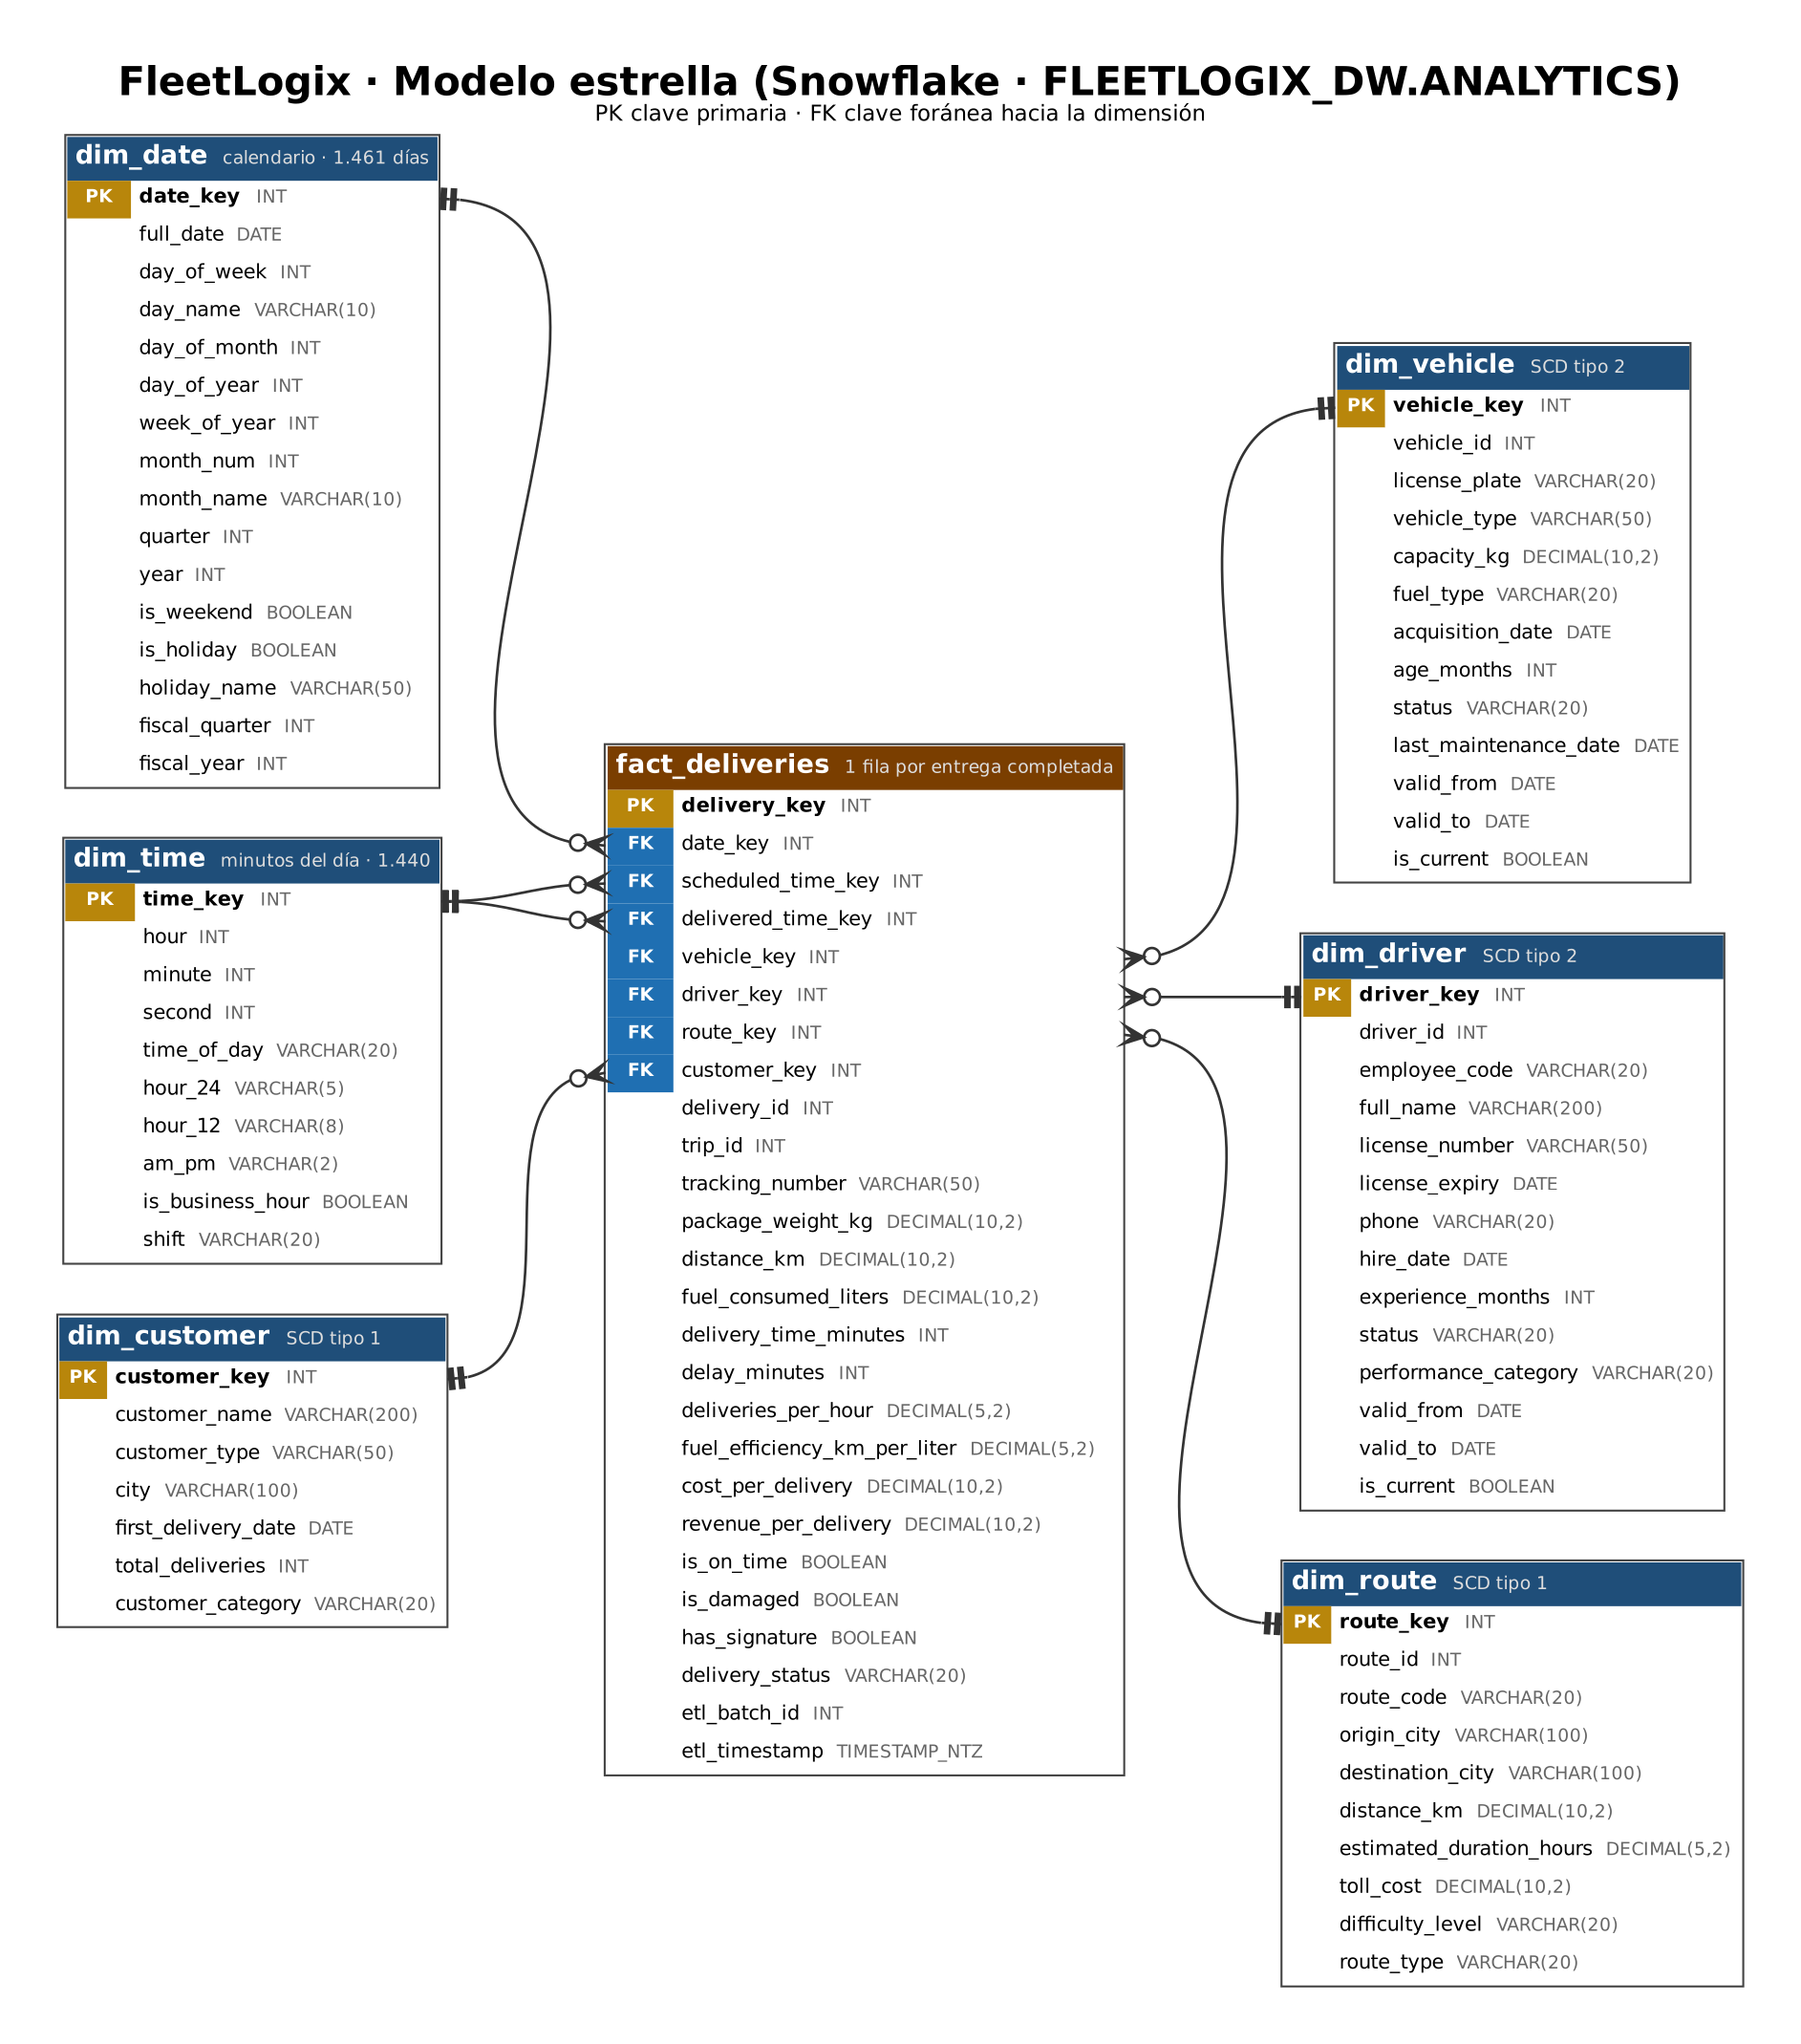

In [2]:
display(Image(filename=str(Path("..") / "3. Documentación" / "diagrama_estrella_fleetlogix.png"), width=900))

| Tabla | Origen | Tipo de historia | Atributos derivados |
|---|---|---|---|
| `fact_deliveries` | `deliveries` + `trips` + `routes` | — (MERGE por `delivery_id`) | tiempos, retraso, puntualidad, entregas por hora, eficiencia, costo e ingreso |
| `dim_date` | Generada en Snowflake | Fija | día de la semana, trimestre, fin de semana, **festivos de Colombia** |
| `dim_time` | Generada en Snowflake | Fija | franja del día, horario laboral, **turno** |
| `dim_vehicle` | `vehicles` + `maintenance` | **SCD tipo 2** (tipo 1 para antigüedad y último mantenimiento) | antigüedad en meses, último mantenimiento |
| `dim_driver` | `drivers` + desempeño en `deliveries` | **SCD tipo 2** (tipo 1 para experiencia) | experiencia en meses, categoría de desempeño |
| `dim_route` | `routes` | SCD tipo 1 | dificultad, tipo de ruta |
| `dim_customer` | `deliveries.customer_name` | SCD tipo 1 | tipo (Empresa / Individual), ciudad, categoría |

**SCD tipo 2** guarda una versión nueva cada vez que cambia un atributo relevante. La versión anterior se cierra (`valid_to`, `is_current = FALSE`) y los hechos quedan unidos a la versión vigente **en la fecha de la entrega**. **SCD tipo 1** sobrescribe el valor.

**Ajustes realizados sobre el script base** (detalle en los comentarios de los scripts):
- **Claves sustitutas con `IDENTITY`** en las dimensiones. El script base guardaba en los hechos los ID de PostgreSQL y el cliente era siempre 1; con SCD tipo 2 un mismo conductor puede tener varias versiones, cada una con su clave.
- **`dim_time` por minuto** (`time_key = HHMM`). El script base calculaba la clave como hora × 100 y perdía los minutos.
- **Festivos de Colombia 2024-2027** en `dim_date`: fijos, trasladados al lunes (Ley Emiliani) y los que dependen de la Pascua.
- **Distancia y combustible del viaje repartidos entre sus entregas.** Así la suma por día, conductor o ruta da el total real; con el valor del viaje en cada entrega, la suma se multiplicaba por 2 a 6 (el mismo problema de la Q9 del avance 2).
- **Dos métricas de tiempo distintas.** `delivery_time_minutes` mide desde la salida del viaje hasta la entrega y `delay_minutes` el retraso sobre la hora programada. El script base usaba la misma diferencia para las dos.

**Criterios de clasificación**, definidos a partir de la distribución de los datos:

| Atributo | Regla |
|---|---|
| `dim_driver.performance_category` | % de entregas puntuales: Alto ≥ 87,5 % · Bajo < 86 % · Medio entre ambos (aprox. un tercio de conductores en cada grupo) |
| `dim_customer.customer_type` | Empresa si el nombre incluye S.A.S., S.A., Ltda o & Cía.; si no, Individual. En los datos no hay clientes de tipo Gobierno |
| `dim_customer.customer_category` | Premium ≥ 120 entregas · Ocasional < 30 · Regular entre ambos |
| `dim_route.difficulty_level` | Fácil < 300 km · Medio 300-800 km · Difícil > 800 km |
| `dim_route.route_type` | Las 50 rutas unen ciudades distintas: Interurbana |

## 3. Configuración de Snowflake

- **Escalado automático:** el warehouse `FLEETLOGIX_WH` (XSMALL) es multi-clúster: arranca con 1 clúster y agrega hasta 3 si las consultas se acumulan en cola. Se suspende después de 60 segundos sin uso y se reactiva solo, así que no consume créditos en reposo.
- **Time Travel de 30 días:** se definió en la base de datos y lo heredan todas las tablas. Permite consultar o recuperar los datos como estaban hasta 30 días atrás (requiere la edición Enterprise).
- **Vistas seguras por rol:** `v_sales_deliveries` (rol `SALES_ANALYST`) y `v_operations_deliveries` (rol `OPERATIONS_ANALYST`). Se prueban en la sección 6.

In [3]:
sf("SHOW WAREHOUSES LIKE 'FLEETLOGIX_WH'")[
    ["name", "size", "min_cluster_count", "max_cluster_count", "scaling_policy", "auto_suspend", "auto_resume"]]

,name,size,min_cluster_count,max_cluster_count,scaling_policy,auto_suspend,auto_resume
0,FLEETLOGIX_WH,X-Small,1,3,STANDARD,60,true


In [4]:
sf("SHOW TABLES IN SCHEMA FLEETLOGIX_DW.ANALYTICS")[["name", "rows", "retention_time"]]

,name,rows,retention_time
0,DAILY_TOTALS,731,30
1,DIM_CUSTOMER,7593,30
2,DIM_DATE,1461,30
3,DIM_DRIVER,407,30
4,DIM_ROUTE,50,30
5,DIM_TIME,1440,30
6,DIM_VEHICLE,200,30
7,FACT_DELIVERIES,399964,30
8,STAGING_DAILY_LOAD,800620,30


## 4. Pipeline ETL

`05_etl_pipeline.py` procesa las entregas completadas de un período y sigue estos pasos:

1. **Extraer** de PostgreSQL las entregas del período, con su viaje, ruta y vehículo, y el estado de las tablas maestras a esa fecha.
2. **Cargar dimensiones:** vehículo y conductor con SCD tipo 2; ruta y cliente con SCD tipo 1 (`MERGE`).
3. **Guardar el lote crudo** en `staging_daily_load`, en formato JSON (`VARIANT`), como respaldo y auditoría.
4. **Transformar:** calcular las métricas y aplicar los controles de calidad.
5. **Cargar los hechos:** subir el lote con `write_pandas` y hacer un `MERGE` en Snowflake que busca la clave de cada dimensión vigente en la fecha de la entrega. Si un día se procesa dos veces, las filas se actualizan y no se duplican.
6. **Precalcular los totales diarios** en `daily_totals`.
7. **Registrar** métricas y errores en `etl_pipeline.log`.

**Controles de calidad:** se descartan los tiempos de entrega negativos, los pesos menores o iguales a 0 o mayores que la capacidad del vehículo y los consumos de combustible no válidos. Después de la carga se cuentan los hechos sin clave de dimensión (deben ser 0).

**Supuestos de negocio:** el modelo de origen no tiene precios ni tarifas, así que se usan los del script base.

| Métrica | Cálculo |
|---|---|
| `cost_per_delivery` | (combustible del viaje × 5.000 COP/litro + peaje) ÷ entregas del viaje |
| `revenue_per_delivery` | 20.000 COP + 500 COP por kg |
| `is_on_time` | retraso de 30 minutos o menos (mismo criterio que en los avances 1 y 2) |
| `deliveries_per_hour` | entregas del viaje ÷ duración del viaje en horas |

**Período de los datos:** los datos llegan hasta el 15/10/2026, así que una corrida "del día anterior" a hoy no tendría entregas. Por eso la ejecución se hace en tres pasos:
- **Carga histórica:** todo lo anterior al 14/10/2026.
- **Carga diaria del 14/10.**
- **Carga diaria del 15/10**, con un cambio en un conductor para mostrar el SCD tipo 2.

## 5. Ejecución

### 5.1 Carga histórica

Para que el notebook se pueda volver a ejecutar desde cero, primero se vacían las tablas que carga el ETL. `dim_date` y `dim_time` no se tocan, porque las genera el script SQL.

In [5]:
for tabla in ["fact_deliveries", "daily_totals", "staging_daily_load",
              "dim_vehicle", "dim_driver", "dim_route", "dim_customer"]:
    sf(f"TRUNCATE TABLE {tabla}")
print("Tablas vacías, listas para la carga histórica")

Tablas vacías, listas para la carga histórica


In [6]:
t0 = time.time()
m_full = etl.run_full(date(2026, 10, 14))
print(f"\nDuración total: {time.time() - t0:.0f} s")

2026-11-09 16:27:59,994 - INFO - Iniciando ETL (carga histórica hasta 2026-10-14) - Batch ID: 1794252479
2026-11-09 16:28:00,003 - INFO - Conectado a PostgreSQL
2026-11-09 16:28:00,323 - INFO - Conectado a Snowflake
2026-11-09 16:28:00,328 - INFO - Extrayendo entregas del 1900-01-01 al 2026-10-13...
2026-11-09 16:28:02,104 - INFO - Extraídos 398,925 registros
2026-11-09 16:28:02,459 - INFO - Cargando dimensiones...
2026-11-09 16:28:08,786 - INFO - dim_vehicle: 200 versiones insertadas (0 por cambios)
2026-11-09 16:28:14,355 - INFO - dim_driver: 400 versiones insertadas (0 por cambios)
2026-11-09 16:28:21,701 - INFO - Dimensiones actualizadas
2026-11-09 16:28:40,849 - INFO - Staging: 398,925 registros guardados como JSON
2026-11-09 16:28:40,851 - INFO - Transformando entregas...
2026-11-09 16:28:40,901 - INFO - Transformados 398,925 de 398,925 registros (0 rechazados)
2026-11-09 16:28:40,902 - INFO - Cargando tabla de hechos...
2026-11-09 16:28:57,747 - INFO - fact_deliveries: 398,925 i

In [7]:
def resumen(m):
    "Métricas principales de una corrida del ETL."
    claves = ["records_extracted", "records_rejected", "facts_inserted", "facts_updated",
              "facts_without_keys", "scd2_new_versions", "errors", "duration_seconds"]
    return pd.Series({k: m.get(k) for k in claves})

resumen(m_full).to_frame("carga histórica")

,carga histórica
records_extracted,398925
records_rejected,0
facts_inserted,398925
facts_updated,0
facts_without_keys,0
scd2_new_versions,"{'dim_vehicle': 0, 'dim_driver': 0}"
errors,0
duration_seconds,59.0


Distribución de las categorías calculadas por el ETL:

In [8]:
sf('''
    SELECT 'Conductor · desempeño' AS atributo, performance_category AS valor, COUNT(*) AS cantidad
    FROM dim_driver WHERE is_current GROUP BY 2
    UNION ALL
    SELECT 'Cliente · tipo', customer_type, COUNT(*) FROM dim_customer GROUP BY 2
    UNION ALL
    SELECT 'Cliente · categoría', customer_category, COUNT(*) FROM dim_customer GROUP BY 2
    UNION ALL
    SELECT 'Ruta · dificultad', difficulty_level, COUNT(*) FROM dim_route GROUP BY 2
    ORDER BY 1, 3 DESC
''')

,atributo,valor,cantidad
0,Cliente · categoría,Ocasional,4747
1,Cliente · categoría,Regular,2346
2,Cliente · categoría,Premium,500
3,Cliente · tipo,Individual,6305
4,Cliente · tipo,Empresa,1288
5,Conductor · desempeño,Bajo,139
6,Conductor · desempeño,Medio,129
7,Conductor · desempeño,Alto,125
8,Conductor · desempeño,Sin viajes,7
9,Ruta · dificultad,Medio,24


### 5.2 Carga diaria del 14/10/2026

In [9]:
m_14 = etl.run_day(date(2026, 10, 14))

2026-11-09 16:28:59,901 - INFO - Iniciando ETL (carga diaria 2026-10-14) - Batch ID: 1794252539
2026-11-09 16:28:59,911 - INFO - Conectado a PostgreSQL
2026-11-09 16:29:00,202 - INFO - Conectado a Snowflake
2026-11-09 16:29:00,202 - INFO - Extrayendo entregas del 2026-10-14 al 2026-10-14...
2026-11-09 16:29:00,248 - INFO - Extraídos 693 registros
2026-11-09 16:29:00,578 - INFO - Cargando dimensiones...
2026-11-09 16:29:06,450 - INFO - dim_vehicle: 0 versiones insertadas (0 por cambios)
2026-11-09 16:29:12,286 - INFO - dim_driver: 5 versiones insertadas (5 por cambios)
2026-11-09 16:29:19,659 - INFO - Dimensiones actualizadas
2026-11-09 16:29:23,243 - INFO - Staging: 693 registros guardados como JSON
2026-11-09 16:29:23,244 - INFO - Transformando entregas...
2026-11-09 16:29:23,249 - INFO - Transformados 693 de 693 registros (0 rechazados)
2026-11-09 16:29:23,249 - INFO - Cargando tabla de hechos...
2026-11-09 16:29:27,983 - INFO - fact_deliveries: 693 insertados, 0 actualizados
2026-11

### 5.3 SCD tipo 2: cambio de un conductor

Para mostrar el manejo de cambios históricos, se cambia en PostgreSQL el teléfono de un conductor que tiene entregas el 15/10 y después se procesa ese día. El resultado esperado:
- `dim_driver` guarda **dos versiones** de ese conductor.
- Las entregas anteriores quedan unidas a la versión vieja y las del 15/10 a la nueva.

El cambio queda registrado en la base de PostgreSQL. Si el notebook se vuelve a ejecutar, el teléfono alterna entre dos valores, para que siempre haya un cambio que mostrar.

In [10]:
conductor = pg('''
    SELECT t.driver_id, dr.phone
    FROM deliveries d
    JOIN trips t    ON t.trip_id = d.trip_id
    JOIN drivers dr ON dr.driver_id = t.driver_id
    WHERE d.delivery_status = 'delivered' AND d.delivered_datetime::date = '2026-10-15'
    ORDER BY d.delivery_id
    LIMIT 1
''').iloc[0]
driver_id = int(conductor["driver_id"])
nuevo_tel = "3001234567" if conductor["phone"] != "3001234567" else "3007654321"

cur = pg_conn.cursor()
cur.execute("UPDATE drivers SET phone = %s WHERE driver_id = %s", (nuevo_tel, driver_id))
pg_conn.commit()
cur.close()
print(f"Conductor {driver_id}: teléfono {conductor['phone']} → {nuevo_tel}")

# Momento previo a la carga del 15/10 (se usa después para Time Travel)
antes_carga_15 = time.time()

Conductor 258: teléfono 3007654321 → 3001234567


In [11]:
m_15 = etl.run_day(date(2026, 10, 15))

2026-11-09 16:29:29,464 - INFO - Iniciando ETL (carga diaria 2026-10-15) - Batch ID: 1794252569
2026-11-09 16:29:29,486 - INFO - Conectado a PostgreSQL
2026-11-09 16:29:30,387 - INFO - Conectado a Snowflake
2026-11-09 16:29:30,388 - INFO - Extrayendo entregas del 2026-10-15 al 2026-10-15...
2026-11-09 16:29:30,430 - INFO - Extraídos 346 registros
2026-11-09 16:29:30,763 - INFO - Cargando dimensiones...
2026-11-09 16:29:36,849 - INFO - dim_vehicle: 0 versiones insertadas (0 por cambios)
2026-11-09 16:29:42,803 - INFO - dim_driver: 2 versiones insertadas (2 por cambios)
2026-11-09 16:29:50,379 - INFO - Dimensiones actualizadas
2026-11-09 16:29:53,861 - INFO - Staging: 346 registros guardados como JSON
2026-11-09 16:29:53,862 - INFO - Transformando entregas...
2026-11-09 16:29:53,866 - INFO - 43 entregas de viajes en curso: sin métricas de viaje
2026-11-09 16:29:53,867 - INFO - Transformados 346 de 346 registros (0 rechazados)
2026-11-09 16:29:53,867 - INFO - Cargando tabla de hechos...
2

In [12]:
sf(f'''
    SELECT driver_key, driver_id, full_name, phone, performance_category,
           valid_from, valid_to, is_current
    FROM dim_driver
    WHERE driver_id = {driver_id}
    ORDER BY valid_from
''')

,driver_key,driver_id,full_name,phone,performance_category,valid_from,valid_to,is_current
0,1175,258,Fernanda Méndez,3007654321,Medio,1900-01-01,2026-10-14,False
1,1550,258,Fernanda Méndez,3001234567,Medio,2026-10-15,9999-12-31,True


In [13]:
sf(f'''
    SELECT dr.driver_key, dr.phone, dr.is_current,
           COUNT(*) AS entregas, MIN(d.full_date) AS desde, MAX(d.full_date) AS hasta
    FROM fact_deliveries f
    JOIN dim_driver dr ON f.driver_key = dr.driver_key
    JOIN dim_date d    ON f.date_key = d.date_key
    WHERE dr.driver_id = {driver_id}
    GROUP BY 1, 2, 3
    ORDER BY desde
''')

,driver_key,phone,is_current,entregas,desde,hasta
0,1175,3007654321,False,1343,2024-10-17,2026-10-14
1,1550,3001234567,True,3,2026-10-15,2026-10-15


Además del cambio de teléfono, el ETL recalcula cada día la categoría de desempeño de todos los conductores. Si algún conductor cruza un umbral, también genera una versión nueva. Versiones por conductor:

In [14]:
sf('''
    SELECT versiones, COUNT(*) AS conductores
    FROM (SELECT driver_id, COUNT(*) AS versiones FROM dim_driver GROUP BY driver_id)
    GROUP BY versiones
    ORDER BY versiones
''')

,versiones,conductores
0,1,393
1,2,7


### 5.4 Re-ejecución del mismo día (idempotencia)

Volver a procesar el 15/10 no debe duplicar entregas: el `MERGE` por `delivery_id` actualiza las filas existentes.

In [15]:
filas_antes = sf("SELECT COUNT(*) AS n FROM fact_deliveries").n[0]
m_15b = etl.run_day(date(2026, 10, 15))
filas_despues = sf("SELECT COUNT(*) AS n FROM fact_deliveries").n[0]
pd.DataFrame({"carga histórica": resumen(m_full), "14/10": resumen(m_14),
              "15/10": resumen(m_15), "15/10 (repetida)": resumen(m_15b)})

2026-11-09 16:30:01,582 - INFO - Iniciando ETL (carga diaria 2026-10-15) - Batch ID: 1794252601
2026-11-09 16:30:01,588 - INFO - Conectado a PostgreSQL
2026-11-09 16:30:01,945 - INFO - Conectado a Snowflake
2026-11-09 16:30:01,945 - INFO - Extrayendo entregas del 2026-10-15 al 2026-10-15...
2026-11-09 16:30:01,991 - INFO - Extraídos 346 registros
2026-11-09 16:30:02,363 - INFO - Cargando dimensiones...
2026-11-09 16:30:09,072 - INFO - dim_vehicle: 0 versiones insertadas (0 por cambios)
2026-11-09 16:30:15,365 - INFO - dim_driver: 0 versiones insertadas (0 por cambios)
2026-11-09 16:30:22,942 - INFO - Dimensiones actualizadas
2026-11-09 16:30:27,038 - INFO - Staging: 346 registros guardados como JSON
2026-11-09 16:30:27,039 - INFO - Transformando entregas...
2026-11-09 16:30:27,043 - INFO - 43 entregas de viajes en curso: sin métricas de viaje
2026-11-09 16:30:27,044 - INFO - Transformados 346 de 346 registros (0 rechazados)
2026-11-09 16:30:27,044 - INFO - Cargando tabla de hechos...
2

,carga histórica,14/10,15/10,15/10 (repetida)
records_extracted,398925,693,346,346
records_rejected,0,0,0,0
facts_inserted,398925,693,346,0
facts_updated,0,0,0,346
facts_without_keys,0,0,0,0
scd2_new_versions,"{'dim_vehicle': 0, 'dim_driver': 0}","{'dim_vehicle': 0, 'dim_driver': 5}","{'dim_vehicle': 0, 'dim_driver': 2}","{'dim_vehicle': 0, 'dim_driver': 0}"
errors,0,0,0,0
duration_seconds,59.0,29.5,30.5,31.2


In [16]:
print(f"Filas en fact_deliveries antes: {filas_antes:,} · después de repetir el 15/10: {filas_despues:,}")

Filas en fact_deliveries antes: 399,964 · después de repetir el 15/10: 399,964


## 6. Verificación

### 6.1 Conciliación con PostgreSQL
La cantidad de entregas y las sumas de peso deben coincidir entre el origen y el Data Warehouse.

In [17]:
origen = pg('''
    SELECT COUNT(*) AS entregas, ROUND(SUM(package_weight_kg), 2) AS peso_total_kg,
           COUNT(DISTINCT customer_name) AS clientes
    FROM deliveries WHERE delivery_status = 'delivered'
''')
destino = sf('''
    SELECT COUNT(*) AS entregas, ROUND(SUM(package_weight_kg), 2) AS peso_total_kg,
           COUNT(DISTINCT customer_key) AS clientes
    FROM fact_deliveries
''')
conc = pd.concat([origen.astype(float), destino.astype(float)], keys=["PostgreSQL", "Snowflake"]).droplevel(1).astype(object)
conc.loc["¿Coincide?"] = (conc.iloc[0] == conc.iloc[1]).map({True: "Sí", False: "No"})
conc

,entregas,peso_total_kg,clientes
PostgreSQL,399964.0,188591852.23,7593.0
Snowflake,399964.0,188591852.23,7593.0
¿Coincide?,Sí,Sí,Sí


In [18]:
sf('''
    SELECT 'dim_date' AS tabla, COUNT(*) AS filas FROM dim_date
    UNION ALL SELECT 'dim_time', COUNT(*) FROM dim_time
    UNION ALL SELECT 'dim_vehicle', COUNT(*) FROM dim_vehicle
    UNION ALL SELECT 'dim_driver', COUNT(*) FROM dim_driver
    UNION ALL SELECT 'dim_route', COUNT(*) FROM dim_route
    UNION ALL SELECT 'dim_customer', COUNT(*) FROM dim_customer
    UNION ALL SELECT 'fact_deliveries', COUNT(*) FROM fact_deliveries
    UNION ALL SELECT 'daily_totals', COUNT(*) FROM daily_totals
    UNION ALL SELECT 'staging_daily_load', COUNT(*) FROM staging_daily_load
''')

,tabla,filas
0,dim_date,1461
1,dim_time,1440
2,dim_vehicle,200
3,dim_driver,407
4,dim_route,50
5,dim_customer,7593
6,fact_deliveries,399964
7,daily_totals,731
8,staging_daily_load,400310


In [19]:
# Integridad: hechos sin clave de dimensión y totales diarios contra la tabla de hechos
sf('''
    SELECT
      (SELECT COUNT(*) FROM fact_deliveries
        WHERE date_key IS NULL OR scheduled_time_key IS NULL OR delivered_time_key IS NULL
           OR vehicle_key IS NULL OR driver_key IS NULL OR route_key IS NULL
           OR customer_key IS NULL)                                       AS hechos_sin_clave,
      (SELECT SUM(total_deliveries) FROM daily_totals)                    AS suma_daily_totals,
      (SELECT COUNT(*) FROM fact_deliveries)                              AS filas_fact
''')

,hechos_sin_clave,suma_daily_totals,filas_fact
0,0,399964,399964


### 6.2 Totales diarios precalculados (últimos 7 días)

In [20]:
sf('''
    SELECT d.full_date, d.day_name, t.total_deliveries, t.on_time_pct, t.avg_delay_minutes,
           t.total_distance_km, t.total_cost, t.total_revenue, t.active_drivers
    FROM daily_totals t JOIN dim_date d ON t.date_key = d.date_key
    ORDER BY d.full_date DESC
    LIMIT 7
''')

,full_date,day_name,total_deliveries,on_time_pct,avg_delay_minutes,total_distance_km,total_cost,total_revenue,active_drivers
0,2026-10-15,Jueves,346,90.17,13.84,78915.86,98634782.44,92765380.00,99
1,2026-10-14,Miércoles,693,88.60,16.01,116205.12,148039696.67,162038670.00,184
2,2026-10-13,Martes,683,88.14,15.95,118025.07,158290526.78,174922685.00,187
3,2026-10-12,Lunes,483,91.51,14.64,68375.48,94453145.77,140012215.00,136
4,2026-10-11,Domingo,411,85.89,18.00,74831.69,104386804.26,104254125.00,113
5,2026-10-10,Sábado,585,86.32,19.61,99696.08,137819005.72,155979995.00,165
6,2026-10-09,Viernes,704,85.37,19.31,120697.38,163243579.14,181276840.00,191


### 6.3 Staging en JSON
Cada lote se guarda tal como se extrajo, en una columna `VARIANT`. Se consulta con la notación `columna:campo::tipo`.

In [21]:
sf('''
    SELECT etl_batch_id, COUNT(*) AS registros, MIN(load_timestamp) AS cargado
    FROM staging_daily_load GROUP BY 1 ORDER BY 1
''')

,etl_batch_id,registros,cargado
0,1794252479,398925,2026-11-09 11:28:35.685
1,1794252539,693,2026-11-09 11:29:22.547
2,1794252569,346,2026-11-09 11:29:53.204
3,1794252601,346,2026-11-09 11:30:26.277


In [22]:
sf('''
    SELECT raw_data:TRACKING_NUMBER::STRING     AS tracking,
           raw_data:CUSTOMER_NAME::STRING       AS cliente,
           raw_data:DELIVERY_ADDRESS::STRING    AS direccion,
           raw_data:PACKAGE_WEIGHT_KG::FLOAT    AS peso_kg,
           raw_data:DELIVERED_DATETIME::STRING  AS entregado
    FROM staging_daily_load
    WHERE raw_data:DELIVERED_DATETIME::STRING LIKE '2026-10-15%'
    LIMIT 5
''')

,tracking,cliente,direccion,peso_kg,entregado
0,FL202600399326,Inversiones Pabón S.A.S.,"Av. Sotaquirá # 38-9, Barranquilla",262.61,2026-10-15 00:16:00
1,FL202600399327,Ana Muñoz,"Avenida calle 1ª # 21-4 Este, Barranquilla",168.09,2026-10-15 00:37:00
2,FL202600399328,María Jaimes,"Avenida calle 172 # 4-9 Este, Barranquilla",308.90,2026-10-15 01:43:00
3,FL202600399349,Jhon Álvarez,"Avenida Magdalena # 6-2 Este, Barranquilla",1709.17,2026-10-15 00:26:00
4,FL202600399350,Jhon Herrera Trujillo,"Carrera 86 # 89H-52 Este, Barranquilla",2102.18,2026-10-15 01:35:00


### 6.4 Time Travel
Se compara la cantidad de entregas **actual** con la que había **antes de la carga del 15/10**, consultando la misma tabla en el pasado con `AT(OFFSET => -segundos)`.

In [23]:
segundos = int(time.time() - antes_carga_15) + 5
sf(f'''
    SELECT (SELECT COUNT(*) FROM fact_deliveries AT(OFFSET => -{segundos})) AS antes_de_la_carga_15_10,
           (SELECT COUNT(*) FROM fact_deliveries)                           AS ahora
''')

,antes_de_la_carga_15_10,ahora
0,398925,399964


### 6.5 Vistas seguras por rol
Con el rol `SALES_ANALYST` se puede consultar `v_sales_deliveries` (datos comerciales), pero no la tabla de hechos ni la vista de operaciones. Con `OPERATIONS_ANALYST` se accede a la vista con todo el detalle operativo.

**Roles secundarios:** en las cuentas nuevas de Snowflake, cada sesión activa por defecto **todos** los roles del usuario como roles secundarios (`DEFAULT_SECONDARY_ROLES = ('ALL')`). Así, aunque se cambie a `SALES_ANALYST`, los permisos de `ACCOUNTADMIN` siguen disponibles y la prueba no muestra ninguna restricción. Para probar cada rol por separado se desactivan con `USE SECONDARY ROLES NONE`.

In [24]:
def usar_rol(rol):
    "Activa solo ese rol (sin roles secundarios), o vuelve a ACCOUNTADMIN con todos."
    cur = sf_conn.cursor()
    cur.execute(f"USE ROLE {rol}")
    cur.execute("USE SECONDARY ROLES " + ("ALL" if rol == "ACCOUNTADMIN" else "NONE"))
    cur.close()

def probar(rol, consulta):
    usar_rol(rol)
    try:
        r = sf(consulta)
        return f"permitido ({len(r)} filas de muestra)"
    except Exception as e:
        return "denegado: " + str(e).split(":")[-1].strip()[:80]
    finally:
        usar_rol("ACCOUNTADMIN")

pruebas = []
for rol in ["SALES_ANALYST", "OPERATIONS_ANALYST"]:
    for objeto in ["v_sales_deliveries", "v_operations_deliveries", "fact_deliveries"]:
        pruebas.append({"rol": rol, "objeto": objeto,
                        "resultado": probar(rol, f"SELECT * FROM {objeto} LIMIT 5")})
pd.DataFrame(pruebas)

,rol,objeto,resultado
0,SALES_ANALYST,v_sales_deliveries,permitido (5 filas de muestra)
1,SALES_ANALYST,v_operations_deliveries,denegado: Object 'V_OPERATIONS_DELIVERIES' doe...
2,SALES_ANALYST,fact_deliveries,denegado: Object 'FACT_DELIVERIES' does not ex...
3,OPERATIONS_ANALYST,v_sales_deliveries,denegado: Object 'V_SALES_DELIVERIES' does not...
4,OPERATIONS_ANALYST,v_operations_deliveries,permitido (5 filas de muestra)
5,OPERATIONS_ANALYST,fact_deliveries,denegado: Object 'FACT_DELIVERIES' does not ex...


In [25]:
usar_rol("SALES_ANALYST")
muestra_ventas = sf("SELECT * FROM v_sales_deliveries ORDER BY full_date DESC LIMIT 5")
usar_rol("ACCOUNTADMIN")
muestra_ventas

,full_date,customer_name,customer_type,customer_category,city,package_weight_kg,delivery_status,is_on_time,revenue_per_delivery
0,2026-10-15,Almacenes Durán Ltda.,Empresa,Premium,Cali,175.93,delivered,True,107965.00
1,2026-10-15,José Hernán Díaz Gutiérrez,Individual,Regular,Barranquilla,204.74,delivered,True,122370.00
2,2026-10-15,Juan Caro,Individual,Regular,Barranquilla,1037.20,delivered,True,538600.00
3,2026-10-15,José Bermúdez Bohórquez,Individual,Regular,Barranquilla,368.89,delivered,True,204445.00
4,2026-10-15,Mary Rojas Muñoz,Individual,Regular,Barranquilla,145.69,delivered,True,92845.00


In [26]:
sf("SHOW VIEWS IN SCHEMA FLEETLOGIX_DW.ANALYTICS")[["name", "is_secure", "owner"]]

,name,is_secure,owner
0,V_OPERATIONS_DELIVERIES,true,ACCOUNTADMIN
1,V_SALES_DELIVERIES,true,ACCOUNTADMIN


## 7. Análisis sobre el modelo estrella

Algunas preguntas que el modelo dimensional responde con un JOIN directo a cada dimensión.

### 7.1 Entregas y puntualidad según el tipo de día

In [27]:
tipo_dia = sf('''
    SELECT CASE WHEN d.is_holiday THEN 'Festivo'
                WHEN d.is_weekend THEN 'Fin de semana'
                ELSE 'Laborable' END                          AS tipo_dia,
           COUNT(DISTINCT f.date_key)                          AS dias,
           COUNT(*)                                            AS entregas,
           ROUND(COUNT(*) / COUNT(DISTINCT f.date_key), 0)     AS entregas_por_dia,
           ROUND(100 * AVG(IFF(f.is_on_time, 1, 0)), 1)        AS pct_puntual,
           ROUND(AVG(f.delay_minutes), 1)                      AS retraso_promedio_min
    FROM fact_deliveries f
    JOIN dim_date d ON f.date_key = d.date_key
    GROUP BY 1
    ORDER BY entregas_por_dia DESC
''')
tipo_dia

,tipo_dia,dias,entregas,entregas_por_dia,pct_puntual,retraso_promedio_min
0,Laborable,490,291387,595,86.9,18.4
1,Festivo,35,17252,493,86.5,18.6
2,Fin de semana,206,91325,443,85.6,19.7


Los días laborables concentran la actividad (~595 entregas por día), seguidos por los festivos (~490) y los fines de semana (~440). La puntualidad es algo menor el fin de semana (85,6 % frente a 86,9 % en días laborables), con un retraso promedio un minuto mayor. Los festivos quedan en un punto intermedio: menos volumen que un día laborable, con una puntualidad casi igual.

### 7.2 Entregas y puntualidad por turno (hora programada)

In [28]:
turnos = sf('''
    SELECT t.shift AS turno,
           COUNT(*)                                     AS entregas,
           ROUND(100 * AVG(IFF(f.is_on_time, 1, 0)), 1) AS pct_puntual,
           ROUND(AVG(f.delay_minutes), 1)               AS retraso_promedio_min
    FROM fact_deliveries f
    JOIN dim_time t ON f.scheduled_time_key = t.time_key
    GROUP BY 1
    ORDER BY 1
''')
turnos

,turno,entregas,pct_puntual,retraso_promedio_min
0,Turno 1,114610,86.7,18.6
1,Turno 2,134612,86.7,18.6
2,Turno 3,150742,86.4,18.9


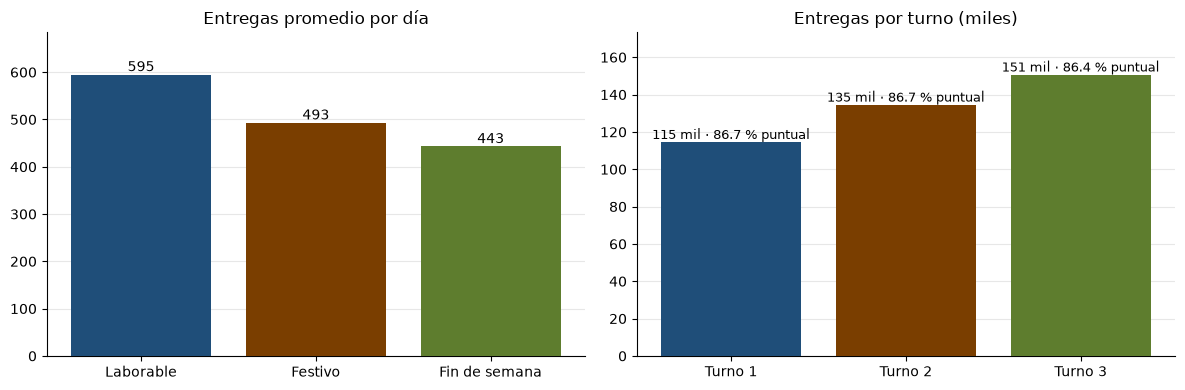

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colores = ["#1F4E79", "#7A3E00", "#5E7D2E"]

axes[0].bar(tipo_dia["tipo_dia"], tipo_dia["entregas_por_dia"].astype(float), color=colores, zorder=3)
axes[0].set_title("Entregas promedio por día")
for i, v in enumerate(tipo_dia["entregas_por_dia"].astype(float)):
    axes[0].text(i, v, f"{v:,.0f}", ha="center", va="bottom")

axes[1].bar(turnos["turno"], turnos["entregas"].astype(float) / 1000, color=colores, zorder=3)
axes[1].set_title("Entregas por turno (miles)")
for i, (v, p) in enumerate(zip(turnos["entregas"].astype(float) / 1000, turnos["pct_puntual"].astype(float))):
    axes[1].text(i, v, f"{v:,.0f} mil · {p:.1f} % puntual", ha="center", va="bottom", fontsize=9)

for ax in axes:
    ax.grid(axis="y", alpha=0.3, zorder=0)
    ax.spines[["top", "right"]].set_visible(False)
    ax.margins(y=0.15)
plt.tight_layout()
plt.show()

El Turno 3 (22:00 a 05:59) es el que tiene más entregas programadas, lo que coincide con el avance 1: muchos viajes de larga distancia salen de madrugada y entregan a primera hora. La puntualidad es pareja entre turnos (≈ 86,5 %), así que el retraso no depende del turno. Esto confirma lo que mostró la Q8 del avance 2: el retraso es estructural y se repite todos los días.

### 7.3 Costo, ingreso y margen estimados por dificultad de ruta

In [30]:
sf('''
    SELECT r.difficulty_level                                AS dificultad,
           COUNT(DISTINCT r.route_key)                        AS rutas,
           COUNT(*)                                           AS entregas,
           ROUND(AVG(f.cost_per_delivery), 0)                 AS costo_promedio,
           ROUND(AVG(f.revenue_per_delivery), 0)              AS ingreso_promedio,
           ROUND(100 * (SUM(f.revenue_per_delivery) - SUM(f.cost_per_delivery))
                 / SUM(f.revenue_per_delivery), 1)            AS margen_pct
    FROM fact_deliveries f
    JOIN dim_route r ON f.route_key = r.route_key
    GROUP BY 1
    ORDER BY MIN(r.distance_km)
''')

,dificultad,rutas,entregas,costo_promedio,ingreso_promedio,margen_pct
0,Fácil,6,47615,23435,134250,82.5
1,Medio,24,191695,176806,272553,35.1
2,Difícil,20,160654,372537,271738,-37.1


Las cifras dependen de los supuestos del script base, pero la comparación deja una conclusión clara: **la tarifa de ejemplo cobra por peso y no por distancia**. El ingreso promedio es casi igual en rutas medias y difíciles, mientras que el costo (combustible y peajes) se duplica. Con esa tarifa, las rutas de más de 800 km dan pérdida (margen −37 %) y las cortas tienen un margen muy alto. Una tarifa real debería incluir la distancia, y con tarifas reales esta misma consulta mostraría qué rutas son rentables.

## 8. Automatización de la ejecución diaria

El pipeline queda listo para correr todas las noches con la librería `schedule`, como pide la consigna:

```bash
cd ~/Desktop/ProyectoM2_LauraGarmendia
export FLEETLOGIX_DB_PASSWORD="..."              # o se pide por teclado al iniciar
python "2. Scripts/05_etl_pipeline.py" --schedule  # procesa el día anterior todos los días a las 02:00
```

Mientras el proceso está abierto, cada noche a las 02:00 procesa las entregas del día anterior. Otros modos:

| Comando | Uso |
|---|---|
| `python 05_etl_pipeline.py --full --until 2026-10-14` | Carga histórica inicial |
| `python 05_etl_pipeline.py --date 2026-10-15` | Reprocesar un día puntual |
| `python 05_etl_pipeline.py` | Procesar el día anterior una sola vez (para usar con `cron`) |

**Alternativa con cron** (no requiere un proceso abierto):

```
0 2 * * * cd ~/Desktop/ProyectoM2_LauraGarmendia && FLEETLOGIX_DB_PASSWORD=... python3 "2. Scripts/05_etl_pipeline.py"
```

Cada corrida deja su registro en `2. Scripts/etl_pipeline.log` (cantidad de registros extraídos, rechazados y cargados, versiones nuevas por SCD tipo 2, errores y duración). Como el `MERGE` es idempotente, si una noche falla basta con volver a ejecutar ese día con `--date`.

## 9. Evidencia: capturas de Snowsight

snowflake_tablas


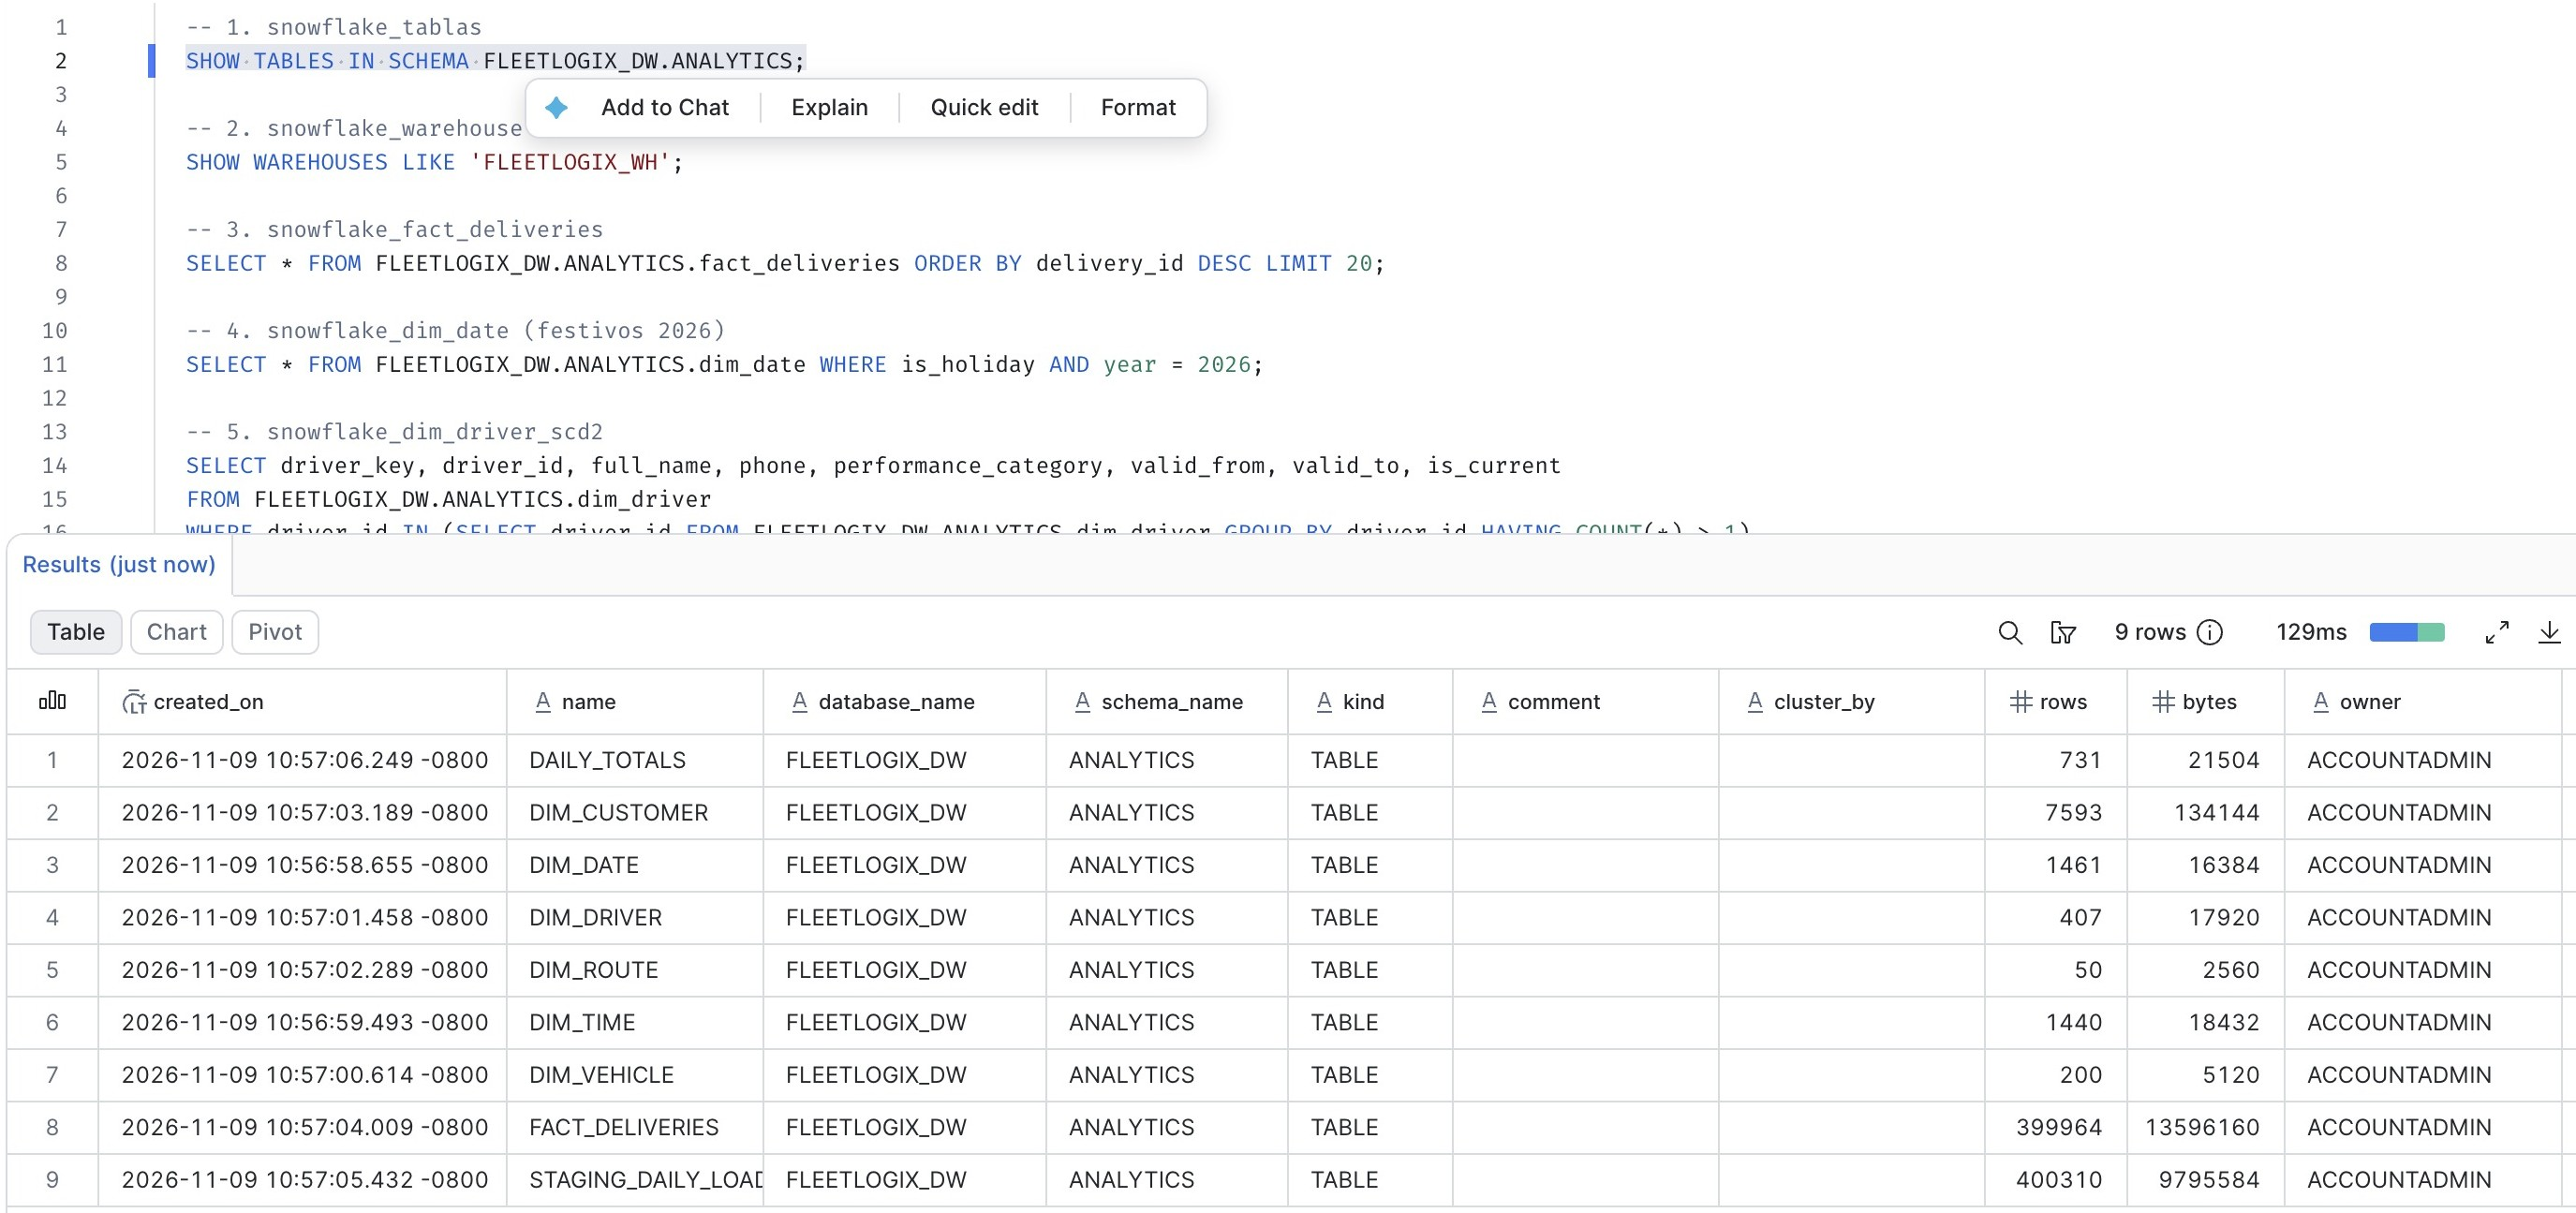

snowflake_warehouse


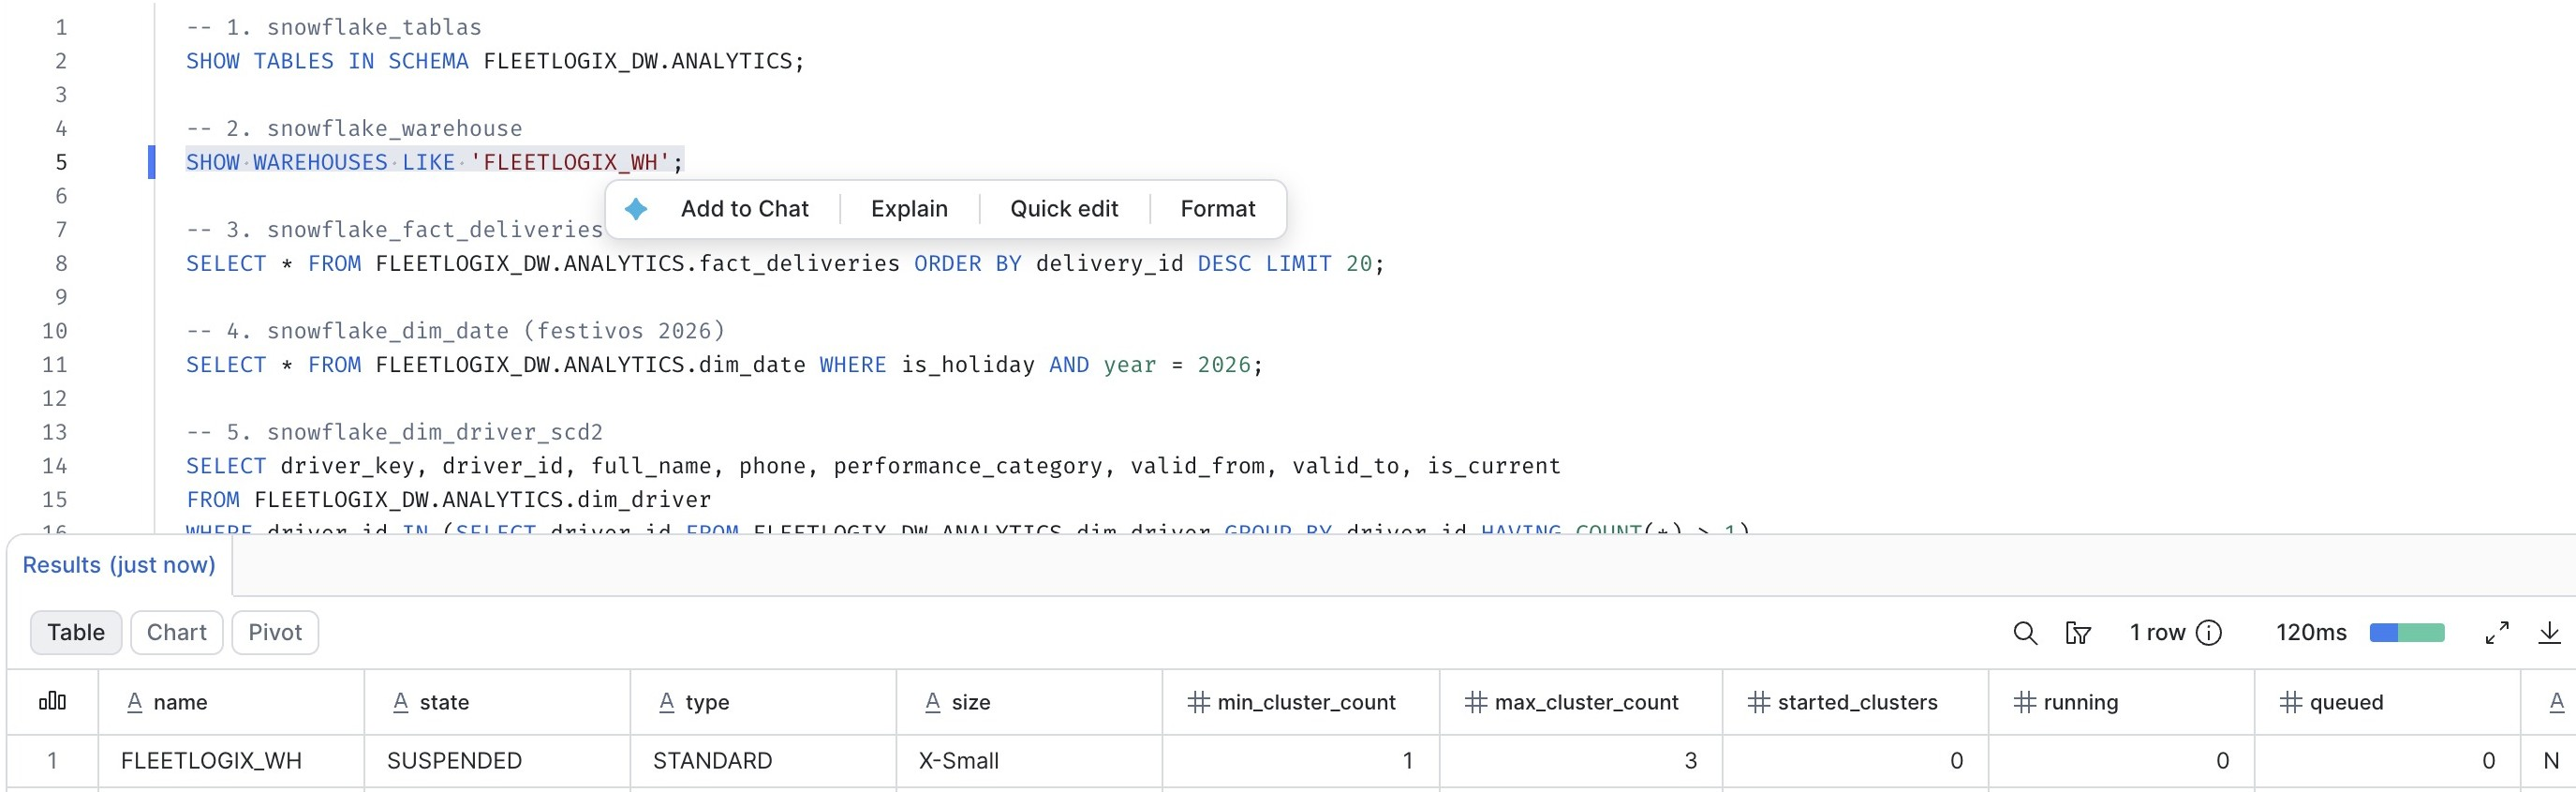

snowflake_fact_deliveries


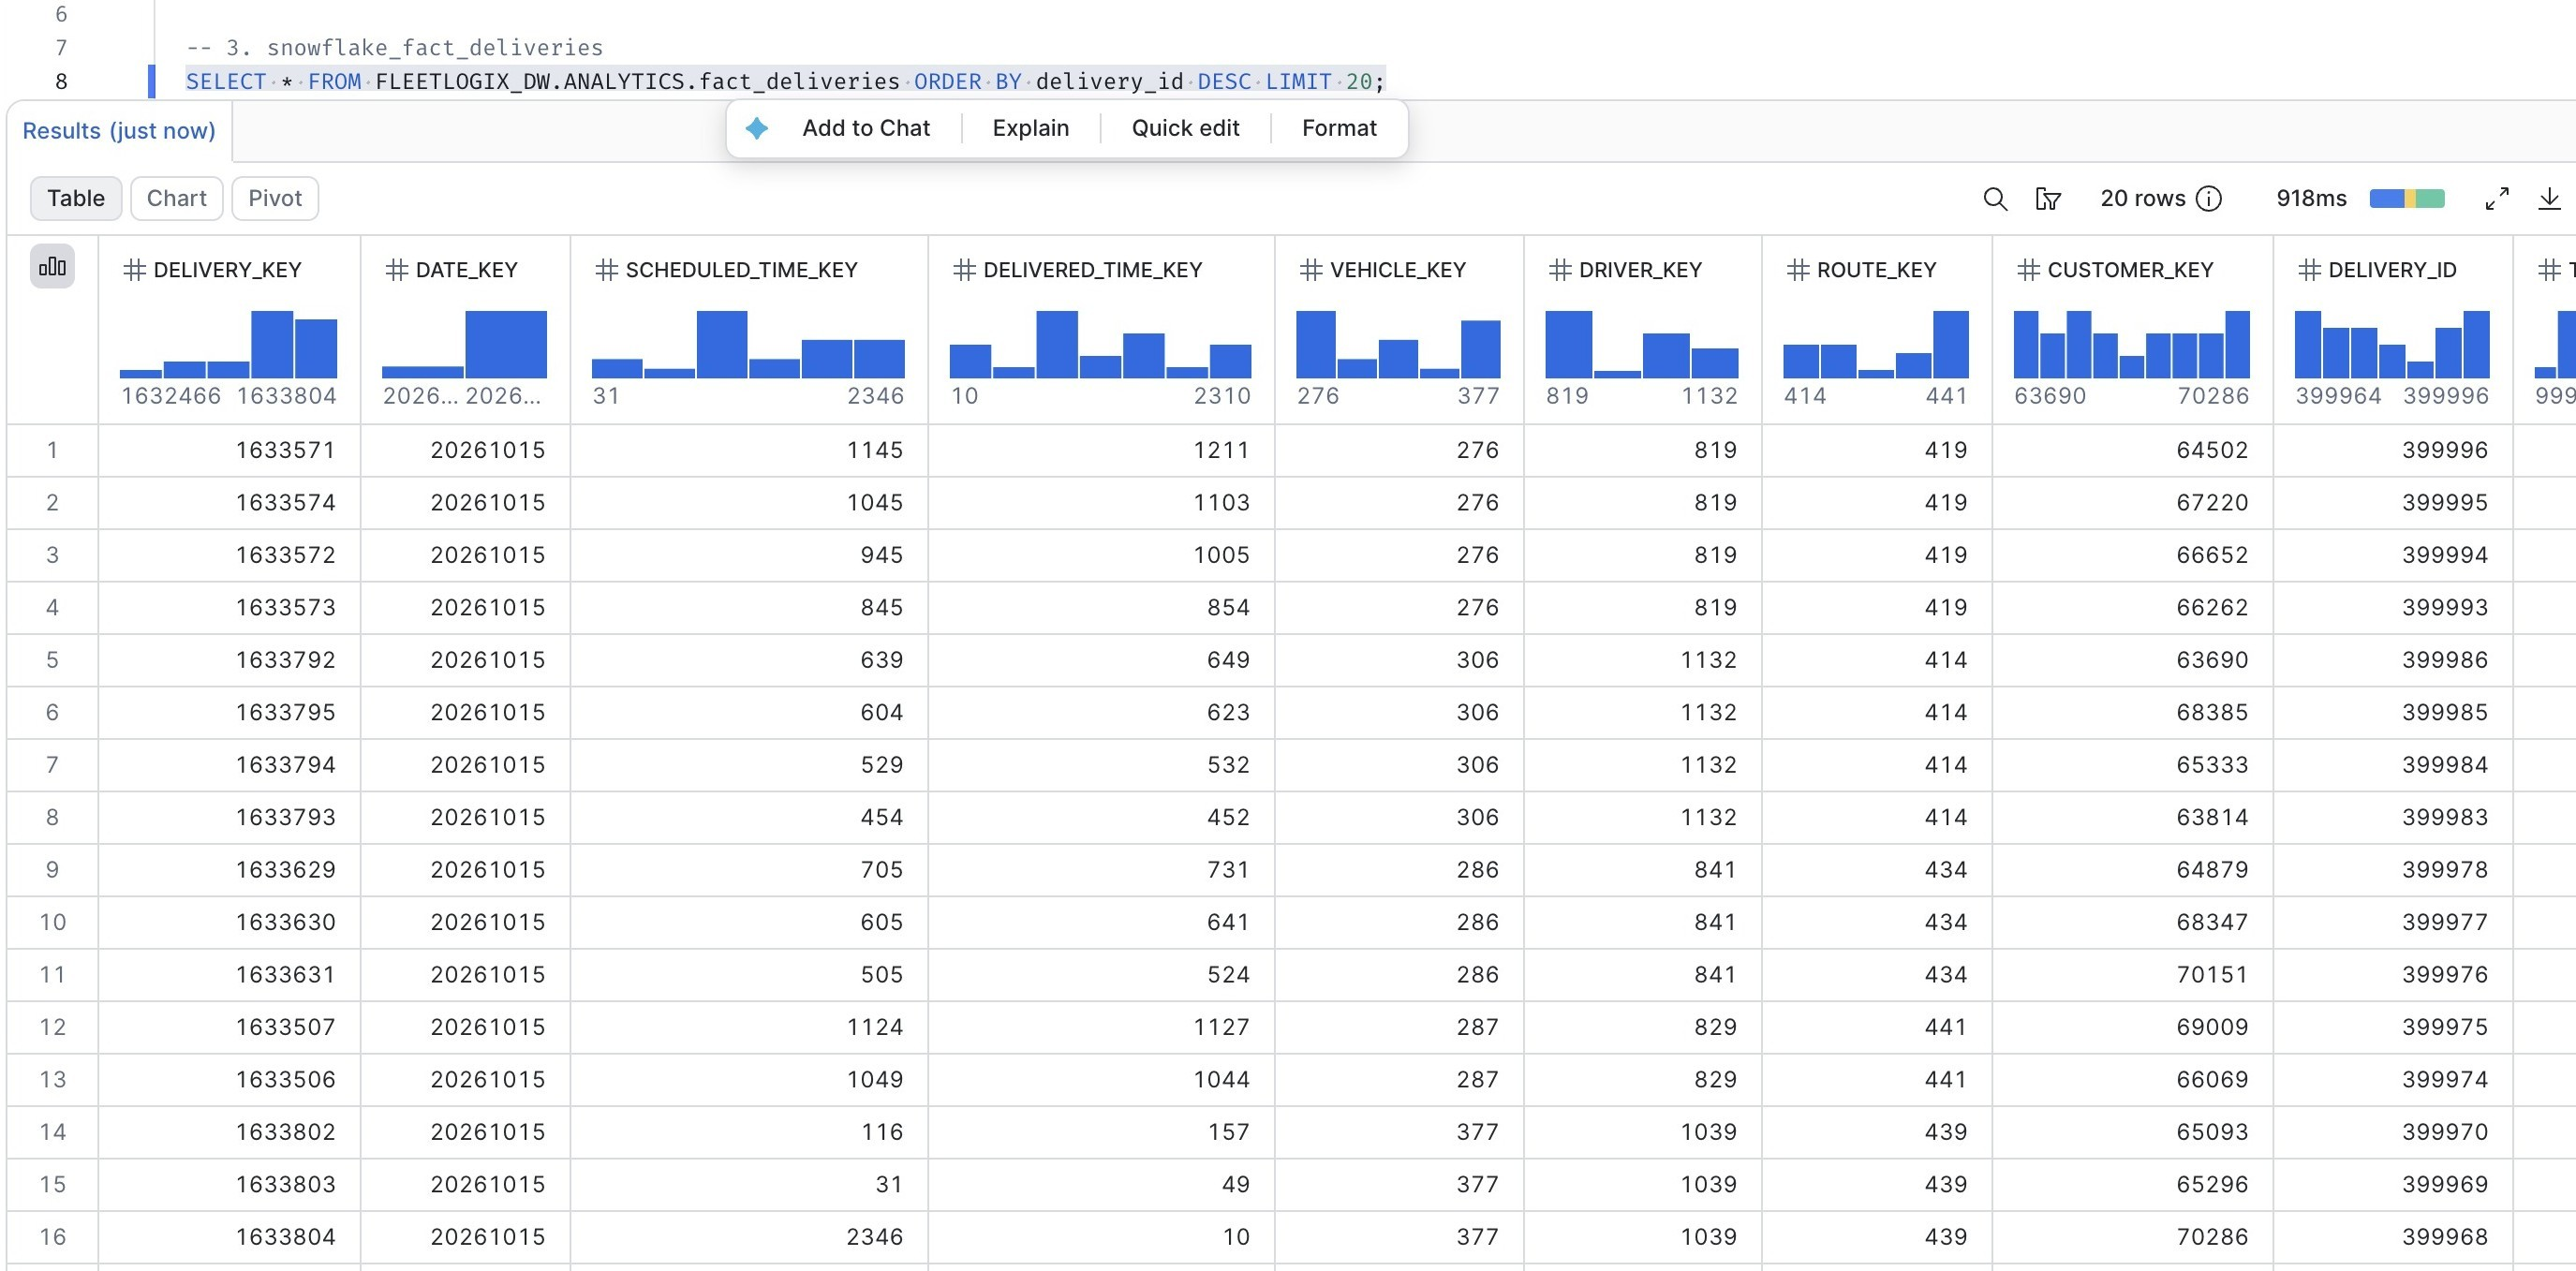

snowflake_dim_date


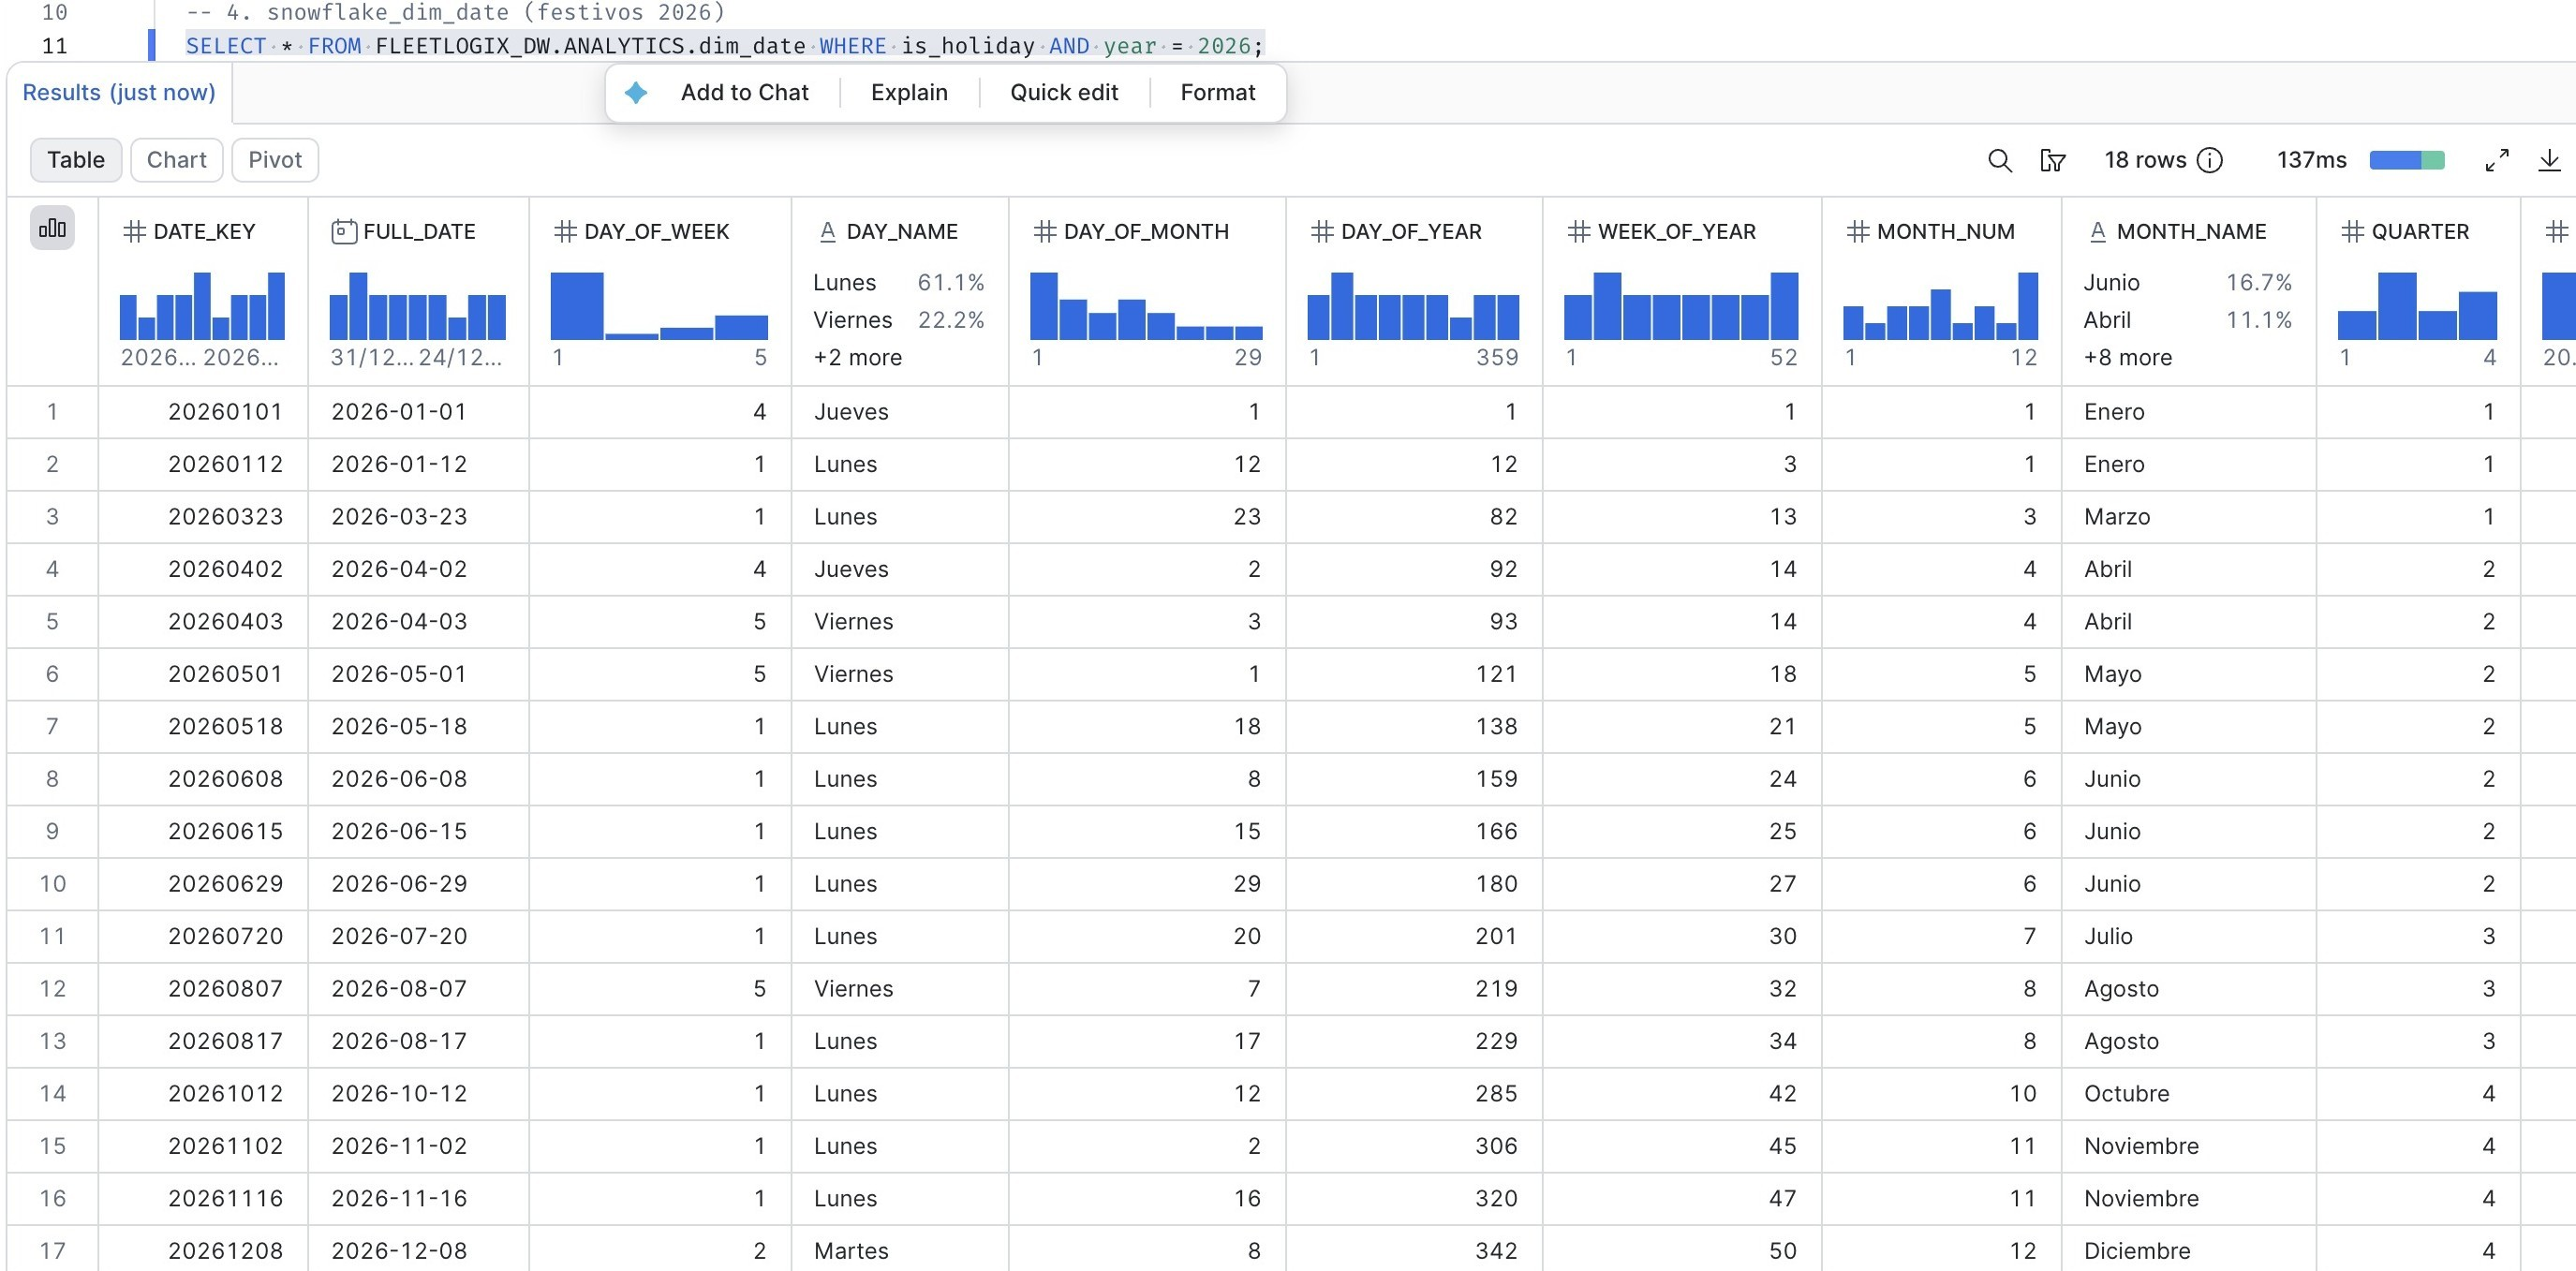

snowflake_dim_driver_scd2


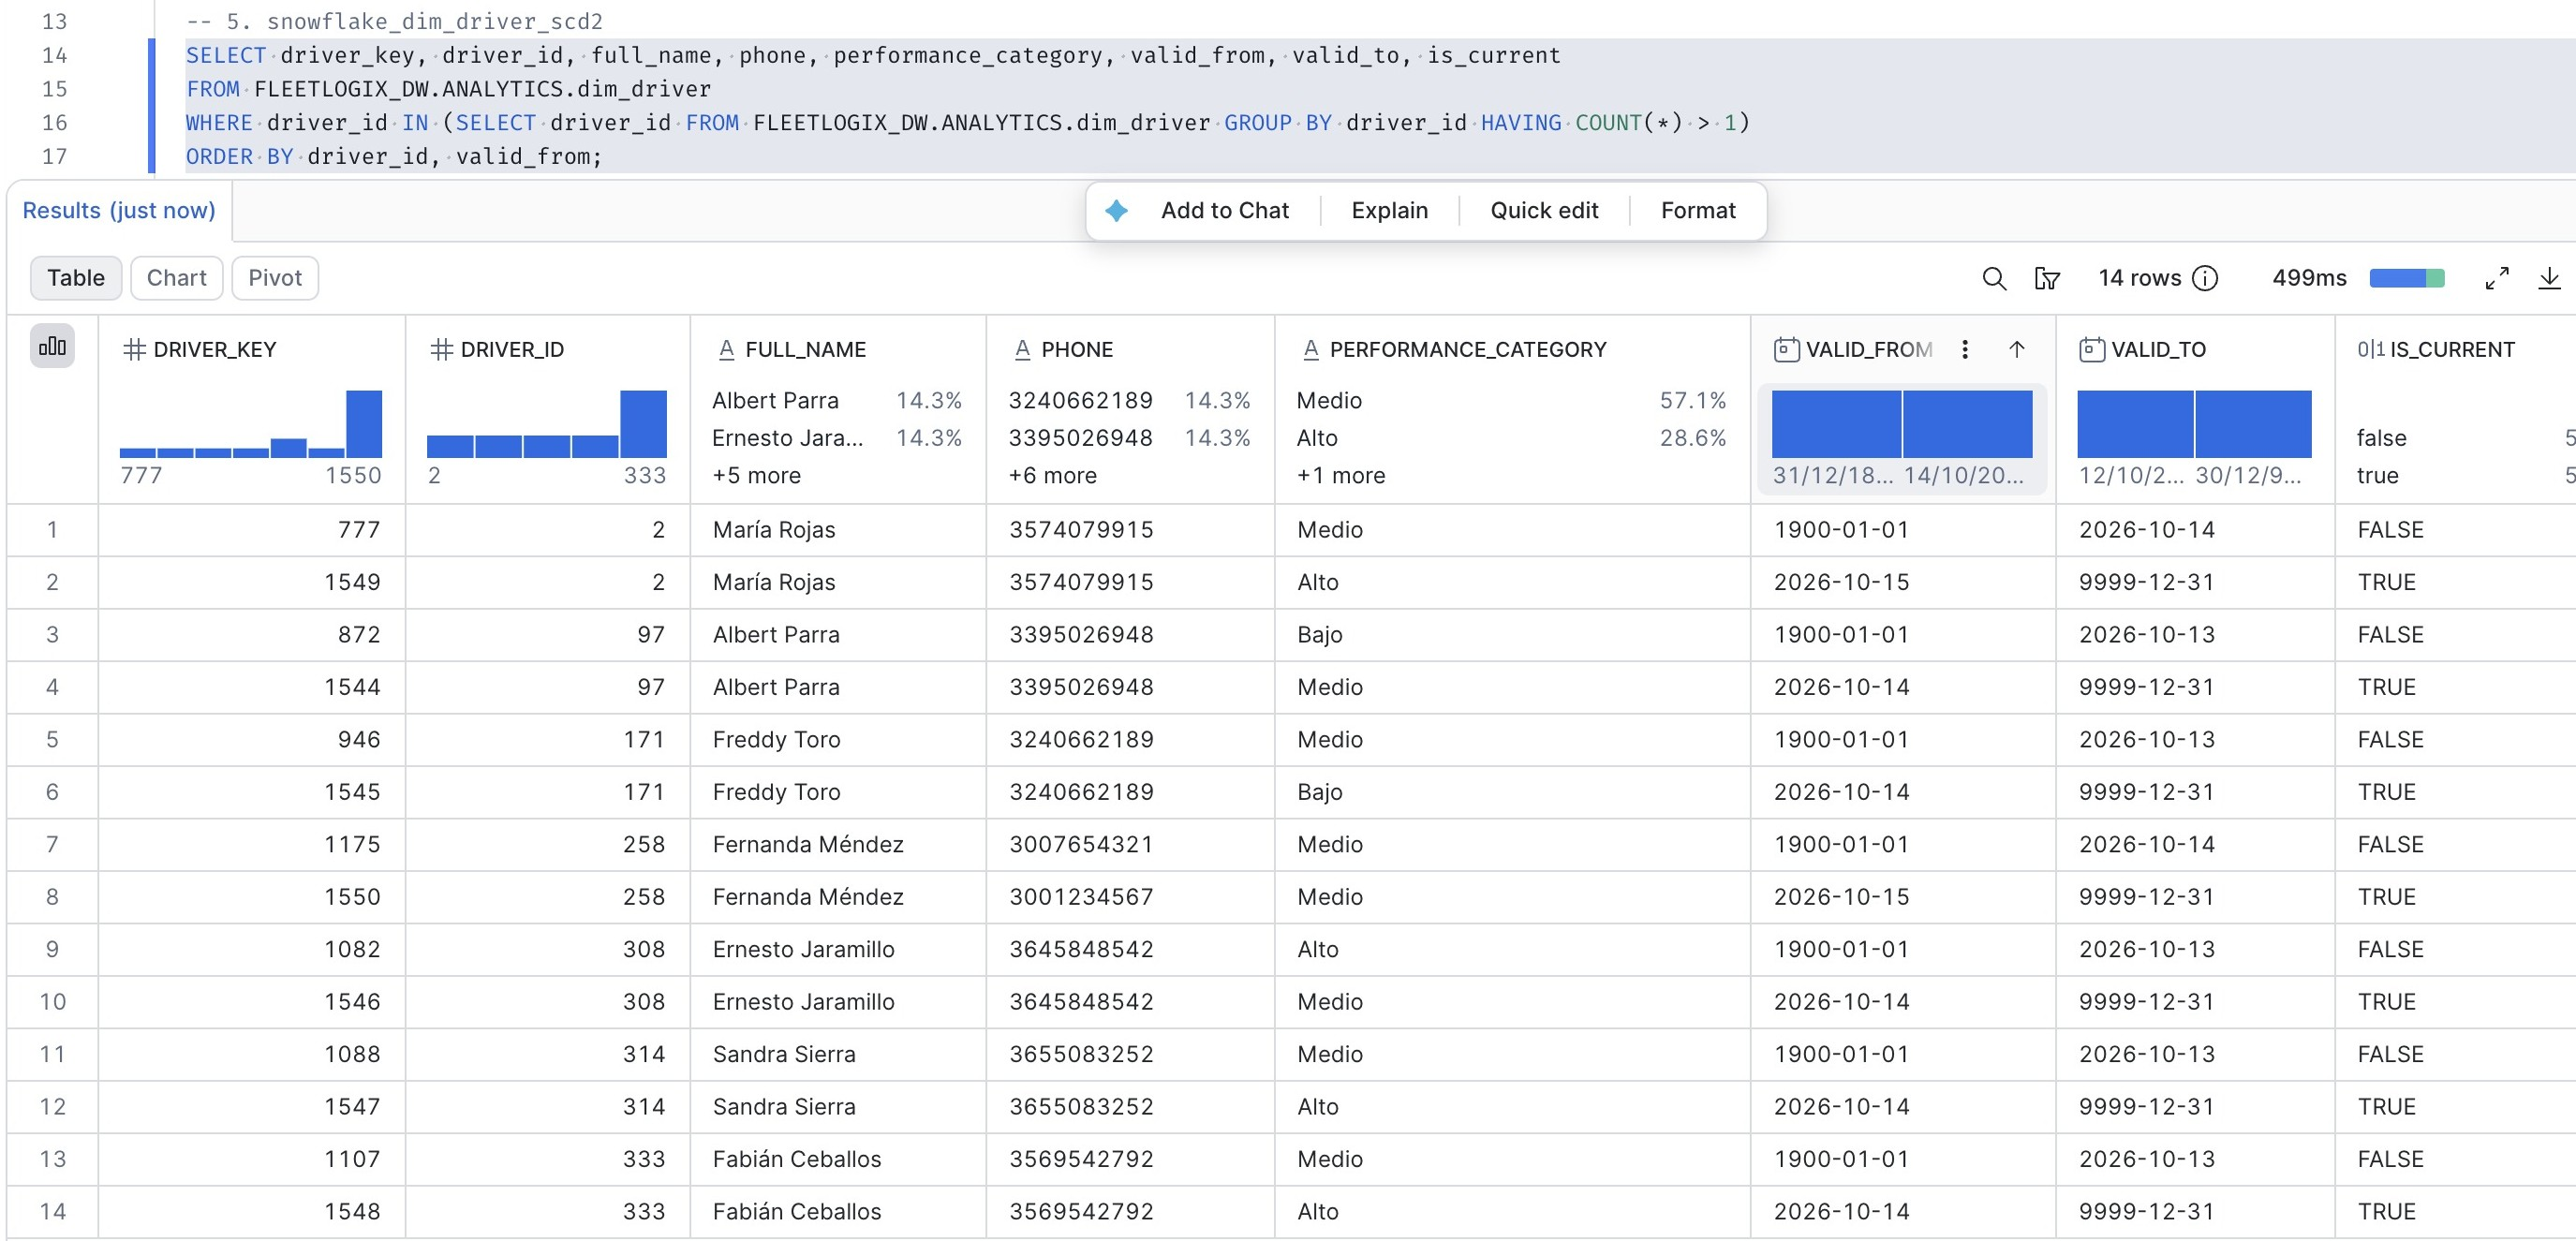

snowflake_vistas


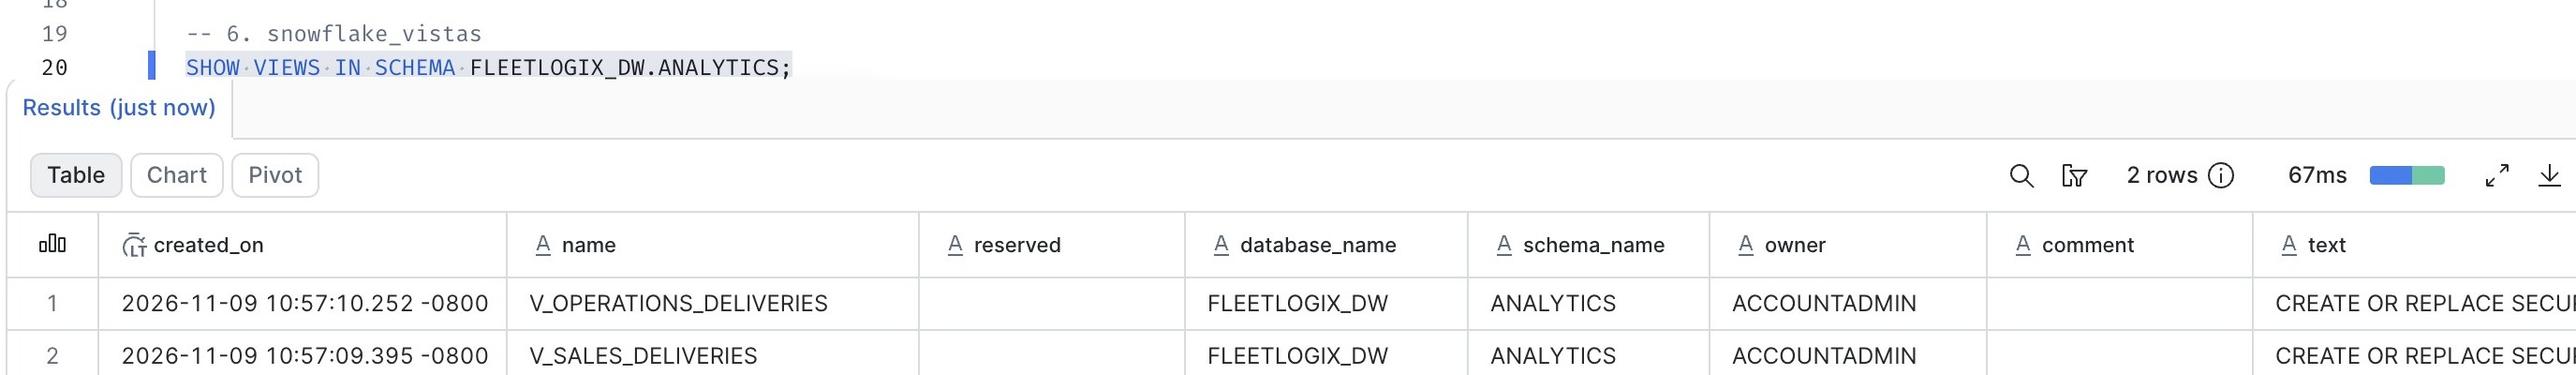

In [33]:
for nombre in ["snowflake_tablas", "snowflake_warehouse", "snowflake_fact_deliveries",
               "snowflake_dim_date", "snowflake_dim_driver_scd2", "snowflake_vistas"]:
    print(nombre)
    captura(nombre)

## 10. Conclusiones

- **El Data Warehouse está operativo en Snowflake:** 6 dimensiones, la tabla de hechos con una fila por entrega completada, staging en JSON y totales diarios. Las cantidades y los pesos coinciden con PostgreSQL y no quedan hechos sin clave de dimensión.
- **El modelo estrella simplifica el análisis:** preguntas como la puntualidad por turno o el margen por tipo de ruta se responden con un JOIN directo a cada dimensión, sin el riesgo de multiplicar filas que apareció en la Q9 del avance 2.
- **La historia queda registrada en dos niveles:** SCD tipo 2 para los cambios en conductores y vehículos, y Time Travel de 30 días para ver cualquier tabla como estaba en un momento anterior.
- **El pipeline es seguro de re-ejecutar:** gracias al `MERGE`, procesar dos veces el mismo día actualiza las filas en lugar de duplicarlas. Esto permite automatizarlo y recuperar fallas sin intervención manual.
- **El acceso se controla por rol:** Ventas ve solo datos comerciales y Operaciones el detalle completo, mediante vistas seguras.
- **Pendiente para un entorno real:** reemplazar los supuestos de costo e ingreso por tarifas reales y agregar `is_damaged` cuando el sistema de origen registre las entregas con daños.

In [32]:
pg_conn.close()
sf_conn.close()
print("Conexiones cerradas")

Conexiones cerradas
